In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import platform
import torch

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/AML_GNN_Project"
)
DATA_DIR = PROJECT_DIR / "data"
D2_RESULTS = PROJECT_DIR / "results"
D3_RESULTS = PROJECT_DIR / "results_deliverable3"
D3_RESULTS.mkdir(parents=True, exist_ok=True)

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nOriginal dataset:")
for filename in [
    "elliptic_txs_features.csv",
    "elliptic_txs_classes.csv",
    "elliptic_txs_edgelist.csv",
]:
    path = DATA_DIR / filename
    print(filename, "FOUND" if path.is_file() else "MISSING")

print("\nDeliverable 2 baseline:")
for prefix in ["xgb", "mlp", "graphsage"]:
    filename = f"{prefix}_adaptation_seed0_metrics.csv"
    path = D2_RESULTS / filename
    print(filename, "FOUND" if path.is_file() else "MISSING")

print("\nNew results directory:", D3_RESULTS)

Mounted at /content/drive
Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4

Original dataset:
elliptic_txs_features.csv FOUND
elliptic_txs_classes.csv FOUND
elliptic_txs_edgelist.csv FOUND

Deliverable 2 baseline:
xgb_adaptation_seed0_metrics.csv FOUND
mlp_adaptation_seed0_metrics.csv FOUND
graphsage_adaptation_seed0_metrics.csv FOUND

New results directory: /content/drive/MyDrive/Colab Notebooks/AML_GNN_Project/results_deliverable3


In [2]:
import json
import numpy as np
import pandas as pd
from IPython.display import display

# Load the original data.
features = pd.read_csv(
    DATA_DIR / "elliptic_txs_features.csv", header=None
)
classes = pd.read_csv(
    DATA_DIR / "elliptic_txs_classes.csv",
    dtype={"class": str}
)
edges = pd.read_csv(DATA_DIR / "elliptic_txs_edgelist.csv")

local_cols = [f"local_{i:02d}" for i in range(93)]
aggregate_cols = [f"aggregate_{i:02d}" for i in range(72)]

assert features.shape[1] == 167
features.columns = (
    ["txId", "time_step"] + local_cols + aggregate_cols
)

# Validate identifiers and labels before merging.
assert not features["txId"].duplicated().any()
assert not classes["txId"].duplicated().any()
assert set(features["txId"]) == set(classes["txId"])
assert set(classes["class"]) == {"1", "2", "unknown"}

nodes = features.merge(
    classes, on="txId", validate="one_to_one", sort=False
)

# Unknown labels remain excluded from supervised targets.
nodes["y"] = nodes["class"].map(
    {"1": 1, "2": 0, "unknown": -1}
).astype(int)

assert np.isfinite(
    nodes[local_cols + aggregate_cols].to_numpy(dtype=float)
).all()

assert (
    nodes["time_step"].between(1, 49)
    & nodes["time_step"].mod(1).eq(0)
).all()

# Validate graph endpoints and snapshot boundaries.
assert list(edges.columns) == ["txId1", "txId2"]
assert not edges.duplicated().any()

node_ids = set(nodes["txId"])
assert set(edges["txId1"]).issubset(node_ids)
assert set(edges["txId2"]).issubset(node_ids)

time_lookup = nodes.set_index("txId")["time_step"]
cross_time_edges = int((
    edges["txId1"].map(time_lookup)
    != edges["txId2"].map(time_lookup)
).sum())
assert cross_time_edges == 0

# Preserve the Deliverable 2 split.
split_rows = []
for name, first, last in [
    ("Training", 1, 30),
    ("Validation", 31, 34),
    ("Testing", 35, 49),
]:
    subset = nodes[nodes["time_step"].between(first, last)]
    split_rows.append({
        "partition": name,
        "steps": f"{first}-{last}",
        "total_nodes": len(subset),
        "labeled": int(subset["y"].ge(0).sum()),
        "illicit": int(subset["y"].eq(1).sum()),
        "licit": int(subset["y"].eq(0).sum()),
        "unknown": int(subset["y"].eq(-1).sum()),
    })

split_summary = pd.DataFrame(split_rows)

# Fail early if the data differ from the verified baseline.
assert len(nodes) == 203769
assert len(edges) == 234355
assert split_summary["labeled"].tolist() == [26905, 2989, 16670]
assert split_summary["illicit"].tolist() == [2954, 508, 1083]

counts_by_step = pd.crosstab(
    nodes["time_step"], nodes["class"]
).reindex(index=range(1, 50), columns=["1", "2", "unknown"],
          fill_value=0)
counts_by_step.columns = ["illicit", "licit", "unknown"]

# Write only to the new Deliverable 3 directory.
split_summary.to_csv(D3_RESULTS / "split_summary.csv", index=False)
counts_by_step.to_csv(D3_RESULTS / "counts_by_step.csv")

schema = {
    "predictor_columns": local_cols,
    "excluded_columns": (
        ["txId", "time_step", "class", "y"] + aggregate_cols
    ),
    "label_mapping": {"1": 1, "2": 0, "unknown": -1},
    "split": {"train": [1, 30], "validation": [31, 34],
              "test": [35, 49]},
    "cross_time_edges": cross_time_edges,
    "neural_scaler_rule": "Fit on labeled training nodes only",
}
(D3_RESULTS / "feature_schema.json").write_text(
    json.dumps(schema, indent=2)
)

print("Deliverable 3 data checks PASSED")
print("Transactions:", len(nodes))
print("Edges:", len(edges))
print("Predictors:", len(local_cols))
print("Cross-time edges:", cross_time_edges)
display(split_summary)
print("Saved preprocessing records to:", D3_RESULTS)

Deliverable 3 data checks PASSED
Transactions: 203769
Edges: 234355
Predictors: 93
Cross-time edges: 0


,partition,steps,total_nodes,labeled,illicit,licit,unknown
0,Training,1-30,123287,26905,2954,23951,96382
1,Validation,31-34,12978,2989,508,2481,9989
2,Testing,35-49,67504,16670,1083,15587,50834


Saved preprocessing records to: /content/drive/MyDrive/Colab Notebooks/AML_GNN_Project/results_deliverable3


XGBOOST

In [3]:
import time
import platform
import xgboost as xgb

from sklearn.metrics import average_precision_score, f1_score

assert torch.cuda.is_available(), "Select a GPU runtime first."

# Preserve the original temporal split.
train_mask = nodes["time_step"].between(1, 30) & nodes["y"].ge(0)
val_mask = nodes["time_step"].between(31, 34) & nodes["y"].ge(0)

X_train = nodes.loc[train_mask, local_cols].astype("float32")
y_train = nodes.loc[train_mask, "y"]
X_val = nodes.loc[val_mask, local_cols].astype("float32")
y_val = nodes.loc[val_mask, "y"]

assert X_train.columns.tolist() == local_cols
assert X_val.columns.tolist() == local_cols

FIXED_CLASS_WEIGHT = float(
    y_train.eq(0).sum() / y_train.eq(1).sum()
)

XGB_D3_DIR = D3_RESULTS / "xgboost"
XGB_D3_DIR.mkdir(exist_ok=True)

# Protect completed runs against accidental replacement.
for seed in [1, 2]:
    run_dir = XGB_D3_DIR / f"seed_{seed}"
    assert not run_dir.exists(), (
        f"{run_dir} already exists. Preserve it before rerunning."
    )

validation_rows = []

for seed in [1, 2]:
    run_dir = XGB_D3_DIR / f"seed_{seed}"
    run_dir.mkdir()

    model = xgb.XGBClassifier(
        n_estimators=150,
        max_depth=4,
        learning_rate=0.05,
        tree_method="hist",
        device="cuda",
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=FIXED_CLASS_WEIGHT,
        random_state=seed,
        n_jobs=2,
    )

    torch.cuda.synchronize()
    start = time.perf_counter()

    model.fit(X_train, y_train)

    torch.cuda.synchronize()
    fit_seconds = time.perf_counter() - start

    val_scores = model.get_booster().predict(
        xgb.DMatrix(X_val)
    )

    assert np.isfinite(val_scores).all()

    # Select the threshold using validation labels only.
    # Prefer the larger threshold when F1 ties.
    threshold_grid = np.round(np.arange(0.05, 1.00, 0.05), 2)

    threshold_results = pd.DataFrame([
        {
            "threshold": float(threshold),
            "validation_f1": f1_score(
                y_val,
                val_scores >= threshold,
                zero_division=0,
            ),
        }
        for threshold in threshold_grid
    ])

    best = threshold_results.sort_values(
        ["validation_f1", "threshold"],
        ascending=[False, False],
    ).iloc[0]

    chosen_threshold = float(best["threshold"])
    validation_ap = float(
        average_precision_score(y_val, val_scores)
    )

    # Save model and validation evidence.
    model.save_model(str(run_dir / "frozen_model.json"))

    validation_predictions = nodes.loc[
        val_mask, ["txId", "time_step", "y"]
    ].copy()

    validation_predictions["score"] = val_scores
    validation_predictions["prediction"] = (
        val_scores >= chosen_threshold
    ).astype(int)

    validation_predictions.to_csv(
        run_dir / "validation_predictions.csv", index=False
    )
    threshold_results.to_csv(
        run_dir / "validation_threshold_search.csv", index=False
    )

    settings = {
        "model": "XGBoost",
        "seed": seed,
        "training_steps": [1, 30],
        "validation_steps": [31, 34],
        "predictor_columns": local_cols,
        "threshold": chosen_threshold,
        "validation_AP": validation_ap,
        "validation_F1": float(best["validation_f1"]),
        "positive_class_weight": FIXED_CLASS_WEIGHT,
        "fit_seconds": fit_seconds,
        "python": platform.python_version(),
        "xgboost": xgb.__version__,
        "gpu": torch.cuda.get_device_name(0),
        "parameters": {
            "n_estimators": 150,
            "max_depth": 4,
            "learning_rate": 0.05,
            "subsample": 1.0,
            "colsample_bytree": 1.0,
        },
    }

    (run_dir / "run_info.json").write_text(
        json.dumps(settings, indent=2)
    )

    validation_rows.append({
        "seed": seed,
        "validation_AP": validation_ap,
        "validation_F1": float(best["validation_f1"]),
        "threshold": chosen_threshold,
        "fit_seconds": fit_seconds,
    })

xgb_validation_summary = pd.DataFrame(validation_rows)
xgb_validation_summary.to_csv(
    XGB_D3_DIR / "validation_summary.csv", index=False
)

print("XGBoost version:", xgb.__version__)
print("Fixed positive-class weight:", FIXED_CLASS_WEIGHT)
display(xgb_validation_summary.round(4))
print("Saved to:", XGB_D3_DIR)

XGBoost version: 3.4.1
Fixed positive-class weight: 8.107989167230873


,seed,validation_AP,validation_F1,threshold,fit_seconds
0,1,0.9634,0.9264,0.7,1.4874
1,2,0.9634,0.9264,0.7,1.9430


Saved to: /content/drive/MyDrive/Colab Notebooks/AML_GNN_Project/results_deliverable3/xgboost


MLP

In [4]:
import copy
import random
import joblib
from torch import nn
from sklearn.preprocessing import StandardScaler

D3_DEVICE = torch.device("cuda")
MLP_D3_DIR = D3_RESULTS / "mlp"
MLP_D3_DIR.mkdir(exist_ok=True)

# Protect existing runs.
for seed in [1, 2]:
    assert not (MLP_D3_DIR / f"seed_{seed}").exists(), (
        f"MLP seed {seed} already exists. Preserve it before rerunning."
    )

def set_d3_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# Fit preprocessing on labeled training nodes only.
d3_scaler = StandardScaler()
d3_scaler.fit(nodes.loc[train_mask, local_cols].astype("float32"))

assert d3_scaler.feature_names_in_.tolist() == local_cols

train_array = d3_scaler.transform(
    nodes.loc[train_mask, local_cols].astype("float32")
).astype("float32")

val_array = d3_scaler.transform(
    nodes.loc[val_mask, local_cols].astype("float32")
).astype("float32")

assert np.isfinite(train_array).all()
assert np.isfinite(val_array).all()

mlp_train_x = torch.from_numpy(train_array).to(D3_DEVICE)
mlp_val_x = torch.from_numpy(val_array).to(D3_DEVICE)

mlp_train_y = torch.tensor(
    nodes.loc[train_mask, "y"].to_numpy(),
    dtype=torch.float32,
    device=D3_DEVICE,
)
mlp_val_y = nodes.loc[val_mask, "y"].to_numpy()

joblib.dump(d3_scaler, MLP_D3_DIR / "training_scaler.joblib")

class TransactionMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(93, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.network(x).squeeze(-1)

mlp_validation_rows = []

for seed in [1, 2]:
    set_d3_seed(seed)
    run_dir = MLP_D3_DIR / f"seed_{seed}"
    run_dir.mkdir()

    current_mlp = TransactionMLP().to(D3_DEVICE)
    optimizer = torch.optim.Adam(
        current_mlp.parameters(), lr=0.001, weight_decay=1e-4
    )
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            FIXED_CLASS_WEIGHT,
            dtype=torch.float32,
            device=D3_DEVICE,
        )
    )

    best_ap = -np.inf
    best_epoch = 0
    best_state = None
    no_improvement = 0
    history = []

    torch.cuda.synchronize()
    start = time.perf_counter()

    for epoch in range(1, 201):
        current_mlp.train()
        optimizer.zero_grad(set_to_none=True)

        loss = criterion(current_mlp(mlp_train_x), mlp_train_y)
        assert torch.isfinite(loss), "Non-finite training loss."
        loss.backward()
        optimizer.step()

        current_mlp.eval()
        with torch.no_grad():
            val_scores = torch.sigmoid(
                current_mlp(mlp_val_x)
            ).cpu().numpy()

        assert np.isfinite(val_scores).all()
        val_ap = float(
            average_precision_score(mlp_val_y, val_scores)
        )

        history.append({
            "epoch": epoch,
            "training_loss": float(loss.item()),
            "validation_AP": val_ap,
        })

        # Same early-stopping rule as Deliverable 2.
        if val_ap > best_ap + 1e-5:
            best_ap = val_ap
            best_epoch = epoch
            best_state = copy.deepcopy(current_mlp.state_dict())
            no_improvement = 0
        else:
            no_improvement += 1

        if no_improvement >= 25:
            break

    torch.cuda.synchronize()
    fit_seconds = time.perf_counter() - start

    assert best_state is not None
    current_mlp.load_state_dict(best_state)
    current_mlp.eval()

    with torch.no_grad():
        val_scores = torch.sigmoid(
            current_mlp(mlp_val_x)
        ).cpu().numpy()

    threshold_results = pd.DataFrame([
        {
            "threshold": float(threshold),
            "validation_f1": f1_score(
                mlp_val_y,
                val_scores >= threshold,
                zero_division=0,
            ),
        }
        for threshold in np.round(np.arange(0.05, 1.00, 0.05), 2)
    ])

    best = threshold_results.sort_values(
        ["validation_f1", "threshold"],
        ascending=[False, False],
    ).iloc[0]

    chosen_threshold = float(best["threshold"])
    validation_ap = float(
        average_precision_score(mlp_val_y, val_scores)
    )

    settings = {
        "model": "MLP",
        "seed": seed,
        "selected_epoch": best_epoch,
        "epochs_executed": len(history),
        "threshold": chosen_threshold,
        "validation_AP": validation_ap,
        "validation_F1": float(best["validation_f1"]),
        "positive_class_weight": FIXED_CLASS_WEIGHT,
        "training_with_validation_seconds": fit_seconds,
        "trainable_parameters": sum(
            p.numel() for p in current_mlp.parameters()
        ),
        "training_steps": [1, 30],
        "validation_steps": [31, 34],
        "predictor_columns": local_cols,
        "torch_version": str(torch.__version__),
        "gpu": torch.cuda.get_device_name(0),
        "architecture": [93, 64, 64, 1],
        "dropout": 0.2,
        "learning_rate": 0.001,
        "weight_decay": 1e-4,
        "max_epochs": 200,
        "patience": 25,
        "minimum_AP_gain": 1e-5,
    }

    torch.save(
        {
            "model_state_dict": {
                name: value.detach().cpu()
                for name, value in current_mlp.state_dict().items()
            },
            **settings,
        },
        run_dir / "frozen_model.pt",
    )

    pd.DataFrame(history).to_csv(
        run_dir / "training_history.csv", index=False
    )
    threshold_results.to_csv(
        run_dir / "validation_threshold_search.csv", index=False
    )

    predictions = nodes.loc[
        val_mask, ["txId", "time_step", "y"]
    ].copy()
    predictions["score"] = val_scores
    predictions["prediction"] = (
        val_scores >= chosen_threshold
    ).astype(int)
    predictions.to_csv(
        run_dir / "validation_predictions.csv", index=False
    )

    (run_dir / "run_info.json").write_text(
        json.dumps(settings, indent=2)
    )

    mlp_validation_rows.append({
        "seed": seed,
        "selected_epoch": best_epoch,
        "epochs_executed": len(history),
        "validation_AP": validation_ap,
        "validation_F1": float(best["validation_f1"]),
        "threshold": chosen_threshold,
        "training_seconds": fit_seconds,
    })

    print(f"MLP seed {seed} completed.")

mlp_validation_summary = pd.DataFrame(mlp_validation_rows)
mlp_validation_summary.to_csv(
    MLP_D3_DIR / "validation_summary.csv", index=False
)

print("\nTrainable parameters:", settings["trainable_parameters"])
display(mlp_validation_summary.round(4))
print("Saved to:", MLP_D3_DIR)

MLP seed 1 completed.
MLP seed 2 completed.

Trainable parameters: 10241


,seed,selected_epoch,epochs_executed,validation_AP,validation_F1,threshold,training_seconds
0,1,200,200,0.8840,0.8352,0.8,4.8036
1,2,101,126,0.8706,0.7684,0.7,1.6246


Saved to: /content/drive/MyDrive/Colab Notebooks/AML_GNN_Project/results_deliverable3/mlp


GraphSAGE with seeds 1 and 2

In [5]:
%pip install -q torch-geometric==2.8.1

import torch_geometric
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv

print("PyTorch Geometric:", torch_geometric.__version__)

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PyTorch Geometric: 2.8.1


In [6]:
SAGE_D3_DIR = D3_RESULTS / "graphsage"
SAGE_D3_DIR.mkdir(exist_ok=True)

for seed in [1, 2]:
    assert not (SAGE_D3_DIR / f"seed_{seed}").exists(), (
        f"GraphSAGE seed {seed} already exists. Preserve it before rerunning."
    )

# Reuse the scaler fitted on labeled training nodes in Step 4.
assert d3_scaler.feature_names_in_.tolist() == local_cols

def build_d3_graph(first_step, last_step):
    frame = nodes.loc[
        nodes["time_step"].between(first_step, last_step)
    ].copy()

    # Explicit ID mapping preserves feature/edge/target alignment.
    node_index = pd.Series(
        np.arange(len(frame), dtype=np.int64),
        index=frame["txId"].to_numpy(),
    )

    selected_edges = edges.loc[
        edges["txId1"].isin(node_index.index)
        & edges["txId2"].isin(node_index.index)
    ]

    edge_array = np.stack([
        selected_edges["txId1"].map(node_index).to_numpy(
            dtype=np.int64
        ),
        selected_edges["txId2"].map(node_index).to_numpy(
            dtype=np.int64
        ),
    ])

    x_array = d3_scaler.transform(
        frame[local_cols].astype("float32")
    ).astype("float32")

    assert np.isfinite(x_array).all()

    graph = Data(
        x=torch.from_numpy(x_array),
        edge_index=torch.from_numpy(edge_array),
        y=torch.tensor(frame["y"].to_numpy(), dtype=torch.long),
        tx_id=torch.tensor(
            frame["txId"].to_numpy(), dtype=torch.long
        ),
        time_step=torch.tensor(
            frame["time_step"].to_numpy(), dtype=torch.long
        ),
    )
    graph.labeled_mask = graph.y.ge(0)
    return graph.to(D3_DEVICE)

d3_train_graph = build_d3_graph(1, 30)
d3_val_graph = build_d3_graph(31, 34)

assert d3_train_graph.num_nodes == 123287
assert d3_train_graph.num_edges == 142784
assert d3_val_graph.num_nodes == 12978
assert d3_val_graph.num_edges == 14059

assert int(d3_train_graph.labeled_mask.sum().item()) == 26905
assert int(d3_val_graph.labeled_mask.sum().item()) == 2989

# Confirm validation predictions will match the original row order.
np.testing.assert_array_equal(
    d3_val_graph.tx_id[d3_val_graph.labeled_mask].cpu().numpy(),
    nodes.loc[val_mask, "txId"].to_numpy(),
)

print(
    "Training graph:",
    d3_train_graph.num_nodes, "nodes,",
    d3_train_graph.num_edges, "edges"
)
print(
    "Validation graph:",
    d3_val_graph.num_nodes, "nodes,",
    d3_val_graph.num_edges, "edges"
)

joblib.dump(d3_scaler, SAGE_D3_DIR / "training_scaler.joblib")

class TransactionGraphSAGE(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = SAGEConv(93, 64, aggr="mean")
        self.conv2 = SAGEConv(64, 64, aggr="mean")
        self.dropout = nn.Dropout(0.2)
        self.output = nn.Linear(64, 1)

    def forward(self, x, edge_index):
        x = self.dropout(torch.relu(self.conv1(x, edge_index)))
        x = self.dropout(torch.relu(self.conv2(x, edge_index)))
        return self.output(x).squeeze(-1)

sage_val_y = (
    d3_val_graph.y[d3_val_graph.labeled_mask].cpu().numpy()
)
sage_validation_rows = []

for seed in [1, 2]:
    set_d3_seed(seed)
    run_dir = SAGE_D3_DIR / f"seed_{seed}"
    run_dir.mkdir()

    current_sage = TransactionGraphSAGE().to(D3_DEVICE)
    optimizer = torch.optim.Adam(
        current_sage.parameters(), lr=0.001, weight_decay=1e-4
    )
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            FIXED_CLASS_WEIGHT,
            dtype=torch.float32,
            device=D3_DEVICE,
        )
    )

    best_ap = -np.inf
    best_epoch = 0
    best_state = None
    no_improvement = 0
    history = []

    torch.cuda.synchronize()
    start = time.perf_counter()

    for epoch in range(1, 201):
        current_sage.train()
        optimizer.zero_grad(set_to_none=True)

        train_logits = current_sage(
            d3_train_graph.x, d3_train_graph.edge_index
        )

        # Unknown targets never enter supervised loss.
        loss = criterion(
            train_logits[d3_train_graph.labeled_mask],
            d3_train_graph.y[
                d3_train_graph.labeled_mask
            ].float(),
        )

        assert torch.isfinite(loss), "Non-finite training loss."
        loss.backward()
        optimizer.step()

        current_sage.eval()
        with torch.no_grad():
            val_logits = current_sage(
                d3_val_graph.x, d3_val_graph.edge_index
            )
            val_scores = torch.sigmoid(
                val_logits[d3_val_graph.labeled_mask]
            ).cpu().numpy()

        assert np.isfinite(val_scores).all()
        val_ap = float(
            average_precision_score(sage_val_y, val_scores)
        )

        history.append({
            "epoch": epoch,
            "training_loss": float(loss.item()),
            "validation_AP": val_ap,
        })

        if val_ap > best_ap + 1e-5:
            best_ap = val_ap
            best_epoch = epoch
            best_state = copy.deepcopy(current_sage.state_dict())
            no_improvement = 0
        else:
            no_improvement += 1

        if no_improvement >= 25:
            break

    torch.cuda.synchronize()
    fit_seconds = time.perf_counter() - start

    assert best_state is not None
    current_sage.load_state_dict(best_state)
    current_sage.eval()

    with torch.no_grad():
        val_logits = current_sage(
            d3_val_graph.x, d3_val_graph.edge_index
        )
        val_scores = torch.sigmoid(
            val_logits[d3_val_graph.labeled_mask]
        ).cpu().numpy()

    threshold_results = pd.DataFrame([
        {
            "threshold": float(threshold),
            "validation_f1": f1_score(
                sage_val_y,
                val_scores >= threshold,
                zero_division=0,
            ),
        }
        for threshold in np.round(np.arange(0.05, 1.00, 0.05), 2)
    ])

    best = threshold_results.sort_values(
        ["validation_f1", "threshold"],
        ascending=[False, False],
    ).iloc[0]

    chosen_threshold = float(best["threshold"])
    validation_ap = float(
        average_precision_score(sage_val_y, val_scores)
    )

    settings = {
        "model": "GraphSAGE",
        "seed": seed,
        "selected_epoch": best_epoch,
        "epochs_executed": len(history),
        "threshold": chosen_threshold,
        "validation_AP": validation_ap,
        "validation_F1": float(best["validation_f1"]),
        "positive_class_weight": FIXED_CLASS_WEIGHT,
        "training_with_validation_seconds": fit_seconds,
        "trainable_parameters": sum(
            p.numel() for p in current_sage.parameters()
        ),
        "training_steps": [1, 30],
        "validation_steps": [31, 34],
        "predictor_columns": local_cols,
        "torch_version": str(torch.__version__),
        "pyg_version": str(torch_geometric.__version__),
        "gpu": torch.cuda.get_device_name(0),
        "edge_direction": "incoming_original_directed",
        "architecture": [93, 64, 64, 1],
        "aggregation": "mean",
        "dropout": 0.2,
        "learning_rate": 0.001,
        "weight_decay": 1e-4,
        "max_epochs": 200,
        "patience": 25,
        "minimum_AP_gain": 1e-5,
    }

    torch.save(
        {
            "model_state_dict": {
                name: value.detach().cpu()
                for name, value in current_sage.state_dict().items()
            },
            **settings,
        },
        run_dir / "frozen_model.pt",
    )

    pd.DataFrame(history).to_csv(
        run_dir / "training_history.csv", index=False
    )
    threshold_results.to_csv(
        run_dir / "validation_threshold_search.csv", index=False
    )

    predictions = nodes.loc[
        val_mask, ["txId", "time_step", "y"]
    ].copy()
    predictions["score"] = val_scores
    predictions["prediction"] = (
        val_scores >= chosen_threshold
    ).astype(int)
    predictions.to_csv(
        run_dir / "validation_predictions.csv", index=False
    )

    (run_dir / "run_info.json").write_text(
        json.dumps(settings, indent=2)
    )

    sage_validation_rows.append({
        "seed": seed,
        "selected_epoch": best_epoch,
        "epochs_executed": len(history),
        "validation_AP": validation_ap,
        "validation_F1": float(best["validation_f1"]),
        "threshold": chosen_threshold,
        "training_seconds": fit_seconds,
    })

    print(f"GraphSAGE seed {seed} completed.")

sage_validation_summary = pd.DataFrame(sage_validation_rows)
sage_validation_summary.to_csv(
    SAGE_D3_DIR / "validation_summary.csv", index=False
)

print("\nTrainable parameters:", settings["trainable_parameters"])
display(sage_validation_summary.round(4))
print("Saved to:", SAGE_D3_DIR)

Training graph: 123287 nodes, 142784 edges
Validation graph: 12978 nodes, 14059 edges
GraphSAGE seed 1 completed.
GraphSAGE seed 2 completed.

Trainable parameters: 20289


,seed,selected_epoch,epochs_executed,validation_AP,validation_F1,threshold,training_seconds
0,1,199,200,0.8935,0.8543,0.90,7.4909
1,2,60,85,0.7989,0.8154,0.85,2.1459


Saved to: /content/drive/MyDrive/Colab Notebooks/AML_GNN_Project/results_deliverable3/graphsage


Evaluate the frozen models

In [7]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    confusion_matrix,
)

def evaluate_d3_predictions(predictions, model_name, policy, seed):
    """Evaluate each snapshot separately on known labels."""
    rows = []

    assert not predictions["txId"].duplicated().any()
    assert predictions["y"].isin([0, 1]).all()
    assert np.isfinite(predictions["score"]).all()
    assert predictions["score"].between(0, 1).all()

    for step, subset in predictions.groupby("time_step", sort=True):
        y = subset["y"].to_numpy()
        scores = subset["score"].to_numpy()
        predicted = subset["prediction"].to_numpy()

        tn, fp, fn, tp = confusion_matrix(
            y, predicted, labels=[0, 1]
        ).ravel()

        row = {
            "model": model_name,
            "policy": policy,
            "seed": int(seed),
            "time_step": int(step),
            "n_labeled": len(subset),
            "n_illicit": int(y.sum()),
            "illicit_prevalence": float(y.mean()),
            "average_precision": (
                float(average_precision_score(y, scores))
                if len(np.unique(y)) == 2 else np.nan
            ),
            "precision": precision_score(
                y, predicted, zero_division=0
            ),
            "recall": recall_score(
                y, predicted, zero_division=0
            ),
            "f1": f1_score(y, predicted, zero_division=0),
            "tn": int(tn),
            "fp": int(fp),
            "fn": int(fn),
            "tp": int(tp),
        }

        # Stable ranking preserves the original order for tied scores.
        order = np.argsort(-scores, kind="stable")

        for budget in [1, 5, 10, 20]:
            k = max(1, int(np.ceil(len(y) * budget / 100)))
            top_labels = y[order[:k]]

            row[f"review_k_{budget}pct"] = k
            row[f"precision_at_{budget}pct"] = float(
                top_labels.mean()
            )
            row[f"recall_at_{budget}pct"] = (
                float(top_labels.sum() / y.sum())
                if y.sum() > 0 else np.nan
            )

        # Compatible with the Deliverable 2 metric name.
        row["review_k"] = row["review_k_10pct"]
        rows.append(row)

    return pd.DataFrame(rows)


test_mask = (
    nodes["time_step"].between(35, 49)
    & nodes["y"].ge(0)
)

test_reference = nodes.loc[
    test_mask, ["txId", "time_step", "y"]
].copy()

assert len(test_reference) == 16670

model_directories = {
    "XGBoost": XGB_D3_DIR,
    "MLP": MLP_D3_DIR,
    "GraphSAGE": SAGE_D3_DIR,
}

# Check every output path before starting.
for model_name, parent in model_directories.items():
    for seed in [1, 2]:
        path = parent / f"seed_{seed}" / "frozen_test_predictions.csv"
        assert not path.exists(), (
            f"Existing evaluation found: {path}. Preserve it before rerunning."
        )

# Verify the saved neural preprocessing matches the current scaler.
for parent in [MLP_D3_DIR, SAGE_D3_DIR]:
    saved_scaler = joblib.load(parent / "training_scaler.joblib")
    assert saved_scaler.feature_names_in_.tolist() == local_cols
    np.testing.assert_array_equal(
        saved_scaler.mean_, d3_scaler.mean_
    )
    np.testing.assert_array_equal(
        saved_scaler.scale_, d3_scaler.scale_
    )

# Build test inputs without fitting any preprocessing.
test_local = nodes.loc[
    test_mask, local_cols
].astype("float32")

mlp_test_x = torch.from_numpy(
    d3_scaler.transform(test_local).astype("float32")
).to(D3_DEVICE)

d3_test_graph = build_d3_graph(35, 49)
assert d3_test_graph.num_nodes == 67504
assert d3_test_graph.num_edges == 77512

np.testing.assert_array_equal(
    d3_test_graph.tx_id[
        d3_test_graph.labeled_mask
    ].cpu().numpy(),
    test_reference["txId"].to_numpy(),
)

all_frozen_metrics = []

for model_name, parent in model_directories.items():
    for seed in [1, 2]:
        run_dir = parent / f"seed_{seed}"
        settings = json.loads(
            (run_dir / "run_info.json").read_text()
        )
        threshold = float(settings["threshold"])

        assert settings["predictor_columns"] == local_cols

        if model_name == "XGBoost":
            booster = xgb.Booster()
            booster.load_model(str(run_dir / "frozen_model.json"))
            booster.set_param({"device": "cuda"})

            scores = booster.predict(xgb.DMatrix(test_local))

        else:
            checkpoint = torch.load(
                run_dir / "frozen_model.pt",
                map_location="cpu",
                weights_only=True,
            )

            if model_name == "MLP":
                fitted_model = TransactionMLP().to(D3_DEVICE)
            else:
                fitted_model = TransactionGraphSAGE().to(D3_DEVICE)

            fitted_model.load_state_dict(
                checkpoint["model_state_dict"]
            )
            fitted_model.eval()

            with torch.no_grad():
                if model_name == "MLP":
                    logits = fitted_model(mlp_test_x)
                else:
                    logits = fitted_model(
                        d3_test_graph.x,
                        d3_test_graph.edge_index,
                    )[d3_test_graph.labeled_mask]

                scores = torch.sigmoid(logits).cpu().numpy()

        assert len(scores) == len(test_reference)

        predictions = test_reference.copy()
        predictions["score"] = scores
        predictions["prediction"] = (
            scores >= threshold
        ).astype(int)
        predictions["model"] = model_name
        predictions["policy"] = "frozen"
        predictions["seed"] = seed

        metrics = evaluate_d3_predictions(
            predictions, model_name, "frozen", seed
        )

        assert len(metrics) == 15

        predictions.to_csv(
            run_dir / "frozen_test_predictions.csv", index=False
        )
        metrics.to_csv(
            run_dir / "frozen_metrics_by_step.csv", index=False
        )

        all_frozen_metrics.append(metrics)
        print(
            f"{model_name}, seed {seed}: "
            f"{len(predictions):,} transactions scored."
        )

d3_frozen_metrics = pd.concat(
    all_frozen_metrics, ignore_index=True
)

assert len(d3_frozen_metrics) == 90
assert not d3_frozen_metrics.duplicated(
    ["model", "policy", "seed", "time_step"]
).any()

d3_frozen_metrics.to_csv(
    D3_RESULTS / "frozen_metrics_seeds1_2.csv",
    index=False,
)

# Average snapshot metrics, matching the Deliverable 2 approach.
phase_metrics = d3_frozen_metrics.copy()
phase_metrics["phase"] = np.select(
    [
        phase_metrics["time_step"].between(35, 42),
        phase_metrics["time_step"].eq(43),
    ],
    ["before_shift", "transition"],
    default="after_shift",
)

frozen_summary = (
    phase_metrics[
        phase_metrics["phase"] != "transition"
    ]
    .groupby(["model", "seed", "phase"], as_index=False)
    .agg(
        mean_AP=("average_precision", "mean"),
        mean_F1=("f1", "mean"),
        mean_recall=("recall", "mean"),
    )
)

frozen_summary.to_csv(
    D3_RESULTS / "frozen_phase_summary_seeds1_2.csv",
    index=False,
)

print("\nVerified frozen model-step results:", len(d3_frozen_metrics))
print("Expected: 90")
display(frozen_summary.round(4))

XGBoost, seed 1: 16,670 transactions scored.
XGBoost, seed 2: 16,670 transactions scored.
MLP, seed 1: 16,670 transactions scored.
MLP, seed 2: 16,670 transactions scored.
GraphSAGE, seed 1: 16,670 transactions scored.
GraphSAGE, seed 2: 16,670 transactions scored.

Verified frozen model-step results: 90
Expected: 90


,model,seed,phase,mean_AP,mean_F1,mean_recall
0,GraphSAGE,1,after_shift,0.1536,0.0174,0.0933
1,GraphSAGE,1,before_shift,0.7159,0.6503,0.6796
2,GraphSAGE,2,after_shift,0.0686,0.0171,0.0433
3,GraphSAGE,2,before_shift,0.6791,0.6287,0.6542
4,MLP,1,after_shift,0.0968,0.0108,0.0933
5,MLP,1,before_shift,0.7456,0.6318,0.8635
6,MLP,2,after_shift,0.1326,0.0247,0.1550
7,MLP,2,before_shift,0.8436,0.5949,0.8763
8,XGBoost,1,after_shift,0.0789,0.0242,0.1240
9,XGBoost,1,before_shift,0.9040,0.7268,0.8772


Run XGBoost adaptation w/ final summary table

In [8]:
ADAPTATION_POLICIES_D3 = ["expanding", "rolling", "recency"]
ROLLING_WINDOW_D3 = 8
RECENCY_HALF_LIFE_D3 = 4

def select_d3_history(score_step, policy):
    times = nodes["time_step"]
    eligible = times.lt(score_step) & nodes["y"].ge(0)

    if policy == "rolling":
        eligible &= times.ge(score_step - ROLLING_WINDOW_D3)
    elif policy not in ["expanding", "recency"]:
        raise ValueError(f"Unknown policy: {policy}")

    history = nodes.loc[eligible].copy()

    assert not history.empty
    assert history["time_step"].max() < score_step
    assert history["y"].nunique() == 2

    weights = np.ones(len(history), dtype=np.float32)

    if policy == "recency":
        age = (
            score_step - 1
            - history["time_step"].to_numpy()
        )
        weights = np.exp2(
            -age / RECENCY_HALF_LIFE_D3
        ).astype(np.float32)
        weights /= weights.mean()

    assert np.isfinite(weights).all()
    assert (weights > 0).all()
    assert np.isclose(weights.mean(), 1.0, atol=1e-6)

    return history, weights


# Check the temporal boundaries before any refitting.
history_checks = []

for policy in ADAPTATION_POLICIES_D3:
    history, weights = select_d3_history(44, policy)
    history_checks.append({
        "policy": policy,
        "prediction_step": 44,
        "first_training_step": int(history["time_step"].min()),
        "last_training_step": int(history["time_step"].max()),
        "training_labels": len(history),
        "mean_weight": float(weights.mean()),
    })

display(pd.DataFrame(history_checks))

# Protect existing adaptation runs.
for seed in [1, 2]:
    output_dir = XGB_D3_DIR / f"seed_{seed}" / "adaptation"
    assert not output_dir.exists(), (
        f"{output_dir} already exists. Preserve it before rerunning."
    )

all_xgb_adaptation_metrics = []

for seed in [1, 2]:
    run_dir = XGB_D3_DIR / f"seed_{seed}"
    output_dir = run_dir / "adaptation"
    output_dir.mkdir()

    settings = json.loads(
        (run_dir / "run_info.json").read_text()
    )
    threshold = float(settings["threshold"])
    class_weight = float(settings["positive_class_weight"])

    protocol = {
        "model": "XGBoost",
        "seed": seed,
        "policies": ADAPTATION_POLICIES_D3,
        "rolling_window": ROLLING_WINDOW_D3,
        "recency_half_life": RECENCY_HALF_LIFE_D3,
        "simulated_label_delay_steps": 1,
        "threshold": threshold,
        "positive_class_weight": class_weight,
        "refit_from_scratch": True,
        "test_steps": [35, 49],
        "predictor_columns": local_cols,
    }
    (output_dir / "protocol.json").write_text(
        json.dumps(protocol, indent=2)
    )

    seed_metrics = []
    seed_predictions = []
    timing_rows = []

    for policy in ADAPTATION_POLICIES_D3:
        policy_dir = output_dir / policy
        policy_dir.mkdir()

        for score_step in range(35, 50):
            history, weights = select_d3_history(
                score_step, policy
            )

            score_rows = nodes.loc[
                nodes["time_step"].eq(score_step)
                & nodes["y"].ge(0)
            ].copy()

            assert not score_rows.empty

            # Same model settings as the frozen run.
            # Only training history/sample weights change.
            adaptive_model = xgb.XGBClassifier(
                **settings["parameters"],
                tree_method="hist",
                device="cuda",
                objective="binary:logistic",
                eval_metric="logloss",
                scale_pos_weight=class_weight,
                random_state=seed,
                n_jobs=2,
            )

            torch.cuda.synchronize()
            start = time.perf_counter()

            adaptive_model.fit(
                history[local_cols].astype("float32"),
                history["y"],
                sample_weight=weights,
            )

            torch.cuda.synchronize()
            refit_seconds = time.perf_counter() - start

            # Generate scores before using current-step targets.
            scores = adaptive_model.get_booster().predict(
                xgb.DMatrix(
                    score_rows[local_cols].astype("float32")
                )
            )
            assert np.isfinite(scores).all()

            predictions = score_rows[
                ["txId", "time_step", "y"]
            ].copy()
            predictions["score"] = scores
            predictions["prediction"] = (
                scores >= threshold
            ).astype(int)
            predictions["model"] = "XGBoost"
            predictions["policy"] = policy
            predictions["seed"] = seed

            metrics = evaluate_d3_predictions(
                predictions, "XGBoost", policy, seed
            )

            # Save each completed step immediately.
            predictions.to_csv(
                policy_dir / f"step_{score_step}_predictions.csv",
                index=False,
            )
            metrics.to_csv(
                policy_dir / f"step_{score_step}_metrics.csv",
                index=False,
            )

            timing_rows.append({
                "model": "XGBoost",
                "seed": seed,
                "policy": policy,
                "score_step": score_step,
                "first_training_step": int(
                    history["time_step"].min()
                ),
                "last_training_step": int(
                    history["time_step"].max()
                ),
                "training_labels": len(history),
                "training_illicit": int(history["y"].sum()),
                "refit_seconds": refit_seconds,
            })

            seed_metrics.append(metrics)
            seed_predictions.append(predictions)

        print(f"Seed {seed}: {policy} completed.")

    seed_metrics_df = pd.concat(seed_metrics, ignore_index=True)
    seed_predictions_df = pd.concat(
        seed_predictions, ignore_index=True
    )

    assert len(seed_metrics_df) == 45
    assert len(seed_predictions_df) == 16670 * 3
    assert not seed_predictions_df.duplicated(
        ["policy", "txId"]
    ).any()

    seed_metrics_df.to_csv(
        output_dir / "metrics_by_step.csv", index=False
    )
    seed_predictions_df.to_csv(
        output_dir / "test_predictions.csv", index=False
    )
    pd.DataFrame(timing_rows).to_csv(
        output_dir / "refit_timing.csv", index=False
    )

    all_xgb_adaptation_metrics.append(seed_metrics_df)

xgb_d3_adaptation_metrics = pd.concat(
    all_xgb_adaptation_metrics, ignore_index=True
)

assert len(xgb_d3_adaptation_metrics) == 90
assert not xgb_d3_adaptation_metrics.duplicated(
    ["model", "policy", "seed", "time_step"]
).any()

xgb_d3_adaptation_metrics.to_csv(
    D3_RESULTS / "xgb_adaptation_metrics_seeds1_2.csv",
    index=False,
)

post_shift_summary = (
    xgb_d3_adaptation_metrics[
        xgb_d3_adaptation_metrics["time_step"].between(44, 49)
    ]
    .groupby(["seed", "policy"], as_index=False)
    .agg(
        mean_AP=("average_precision", "mean"),
        mean_F1=("f1", "mean"),
        mean_recall=("recall", "mean"),
    )
)

post_shift_summary.to_csv(
    XGB_D3_DIR / "adaptation_post_shift_summary.csv",
    index=False,
)

print("\nVerified XGBoost adaptation results:",
      len(xgb_d3_adaptation_metrics))
print("Expected: 90")
display(post_shift_summary.round(4))

,policy,prediction_step,first_training_step,last_training_step,training_labels,mean_weight
0,expanding,44,1,43,41247,1.0
1,rolling,44,36,43,10012,1.0
2,recency,44,1,43,41247,1.0


Seed 1: expanding completed.
Seed 1: rolling completed.
Seed 1: recency completed.
Seed 2: expanding completed.
Seed 2: rolling completed.
Seed 2: recency completed.

Verified XGBoost adaptation results: 90
Expected: 90


,seed,policy,mean_AP,mean_F1,mean_recall
0,1,expanding,0.1983,0.0872,0.1504
1,1,recency,0.4053,0.2685,0.2764
2,1,rolling,0.3164,0.2120,0.1739
3,2,expanding,0.1983,0.0872,0.1504
4,2,recency,0.4053,0.2685,0.2764
5,2,rolling,0.3164,0.2120,0.1739


Run MLP adaptation w/ final summary table

In [9]:
# Reuse preprocessing fitted only on the original training partition.
mlp_adapt_scaler = joblib.load(
    MLP_D3_DIR / "training_scaler.joblib"
)
assert mlp_adapt_scaler.feature_names_in_.tolist() == local_cols

# Protect existing adaptation runs before starting.
for seed in [1, 2]:
    output_dir = MLP_D3_DIR / f"seed_{seed}" / "adaptation"
    assert not output_dir.exists(), (
        f"{output_dir} already exists. Preserve it before rerunning."
    )

all_mlp_adaptation_metrics = []

for seed in [1, 2]:
    run_dir = MLP_D3_DIR / f"seed_{seed}"
    output_dir = run_dir / "adaptation"
    output_dir.mkdir()

    settings = json.loads(
        (run_dir / "run_info.json").read_text()
    )

    threshold = float(settings["threshold"])
    epochs_per_refit = int(settings["selected_epoch"])
    class_weight = float(settings["positive_class_weight"])

    assert settings["predictor_columns"] == local_cols
    assert 1 <= epochs_per_refit <= 200

    protocol = {
        "model": "MLP",
        "seed": seed,
        "policies": ADAPTATION_POLICIES_D3,
        "rolling_window": ROLLING_WINDOW_D3,
        "recency_half_life": RECENCY_HALF_LIFE_D3,
        "simulated_label_delay_steps": 1,
        "threshold": threshold,
        "epochs_per_refit": epochs_per_refit,
        "positive_class_weight": class_weight,
        "refit_from_scratch": True,
        "scaler_refitted": False,
        "test_early_stopping": False,
        "test_steps": [35, 49],
        "predictor_columns": local_cols,
    }
    (output_dir / "protocol.json").write_text(
        json.dumps(protocol, indent=2)
    )

    print(
        f"\nSeed {seed}: {epochs_per_refit} epochs per refit, "
        f"threshold {threshold:.2f}"
    )

    seed_metrics = []
    seed_predictions = []
    timing_rows = []

    for policy in ADAPTATION_POLICIES_D3:
        policy_dir = output_dir / policy
        policy_dir.mkdir()

        for score_step in range(35, 50):
            history, weights = select_d3_history(
                score_step, policy
            )

            score_rows = nodes.loc[
                nodes["time_step"].eq(score_step)
                & nodes["y"].ge(0)
            ].copy()

            assert not score_rows.empty

            train_array = mlp_adapt_scaler.transform(
                history[local_cols].astype("float32")
            ).astype("float32")

            score_array = mlp_adapt_scaler.transform(
                score_rows[local_cols].astype("float32")
            ).astype("float32")

            assert np.isfinite(train_array).all()
            assert np.isfinite(score_array).all()

            train_x = torch.from_numpy(
                train_array
            ).to(D3_DEVICE)
            train_y = torch.tensor(
                history["y"].to_numpy(),
                dtype=torch.float32,
                device=D3_DEVICE,
            )
            train_weights = torch.tensor(
                weights,
                dtype=torch.float32,
                device=D3_DEVICE,
            )
            score_x = torch.from_numpy(
                score_array
            ).to(D3_DEVICE)

            # Reset initialization for every policy and step.
            set_d3_seed(seed)
            adaptive_mlp = TransactionMLP().to(D3_DEVICE)

            optimizer = torch.optim.Adam(
                adaptive_mlp.parameters(),
                lr=settings["learning_rate"],
                weight_decay=settings["weight_decay"],
            )
            criterion = nn.BCEWithLogitsLoss(
                pos_weight=torch.tensor(
                    class_weight,
                    dtype=torch.float32,
                    device=D3_DEVICE,
                ),
                reduction="none",
            )

            torch.cuda.synchronize()
            start = time.perf_counter()

            for epoch in range(epochs_per_refit):
                adaptive_mlp.train()
                optimizer.zero_grad(set_to_none=True)

                individual_losses = criterion(
                    adaptive_mlp(train_x), train_y
                )
                loss = (
                    individual_losses * train_weights
                ).sum() / train_weights.sum()

                assert torch.isfinite(loss), (
                    f"Non-finite loss: seed {seed}, "
                    f"{policy}, step {score_step}"
                )

                loss.backward()
                optimizer.step()

            torch.cuda.synchronize()
            refit_seconds = time.perf_counter() - start

            # Predict before using current-step labels in evaluation.
            adaptive_mlp.eval()
            with torch.no_grad():
                scores = torch.sigmoid(
                    adaptive_mlp(score_x)
                ).cpu().numpy()

            assert np.isfinite(scores).all()

            predictions = score_rows[
                ["txId", "time_step", "y"]
            ].copy()
            predictions["score"] = scores
            predictions["prediction"] = (
                scores >= threshold
            ).astype(int)
            predictions["model"] = "MLP"
            predictions["policy"] = policy
            predictions["seed"] = seed

            metrics = evaluate_d3_predictions(
                predictions, "MLP", policy, seed
            )

            predictions.to_csv(
                policy_dir / f"step_{score_step}_predictions.csv",
                index=False,
            )
            metrics.to_csv(
                policy_dir / f"step_{score_step}_metrics.csv",
                index=False,
            )

            timing_rows.append({
                "model": "MLP",
                "seed": seed,
                "policy": policy,
                "score_step": score_step,
                "first_training_step": int(
                    history["time_step"].min()
                ),
                "last_training_step": int(
                    history["time_step"].max()
                ),
                "training_labels": len(history),
                "training_illicit": int(history["y"].sum()),
                "epochs_per_refit": epochs_per_refit,
                "final_training_loss": float(loss.item()),
                "refit_seconds": refit_seconds,
            })

            seed_metrics.append(metrics)
            seed_predictions.append(predictions)

        print(f"Seed {seed}: {policy} completed.")

    seed_metrics_df = pd.concat(seed_metrics, ignore_index=True)
    seed_predictions_df = pd.concat(
        seed_predictions, ignore_index=True
    )

    assert len(seed_metrics_df) == 45
    assert len(seed_predictions_df) == 16670 * 3
    assert not seed_predictions_df.duplicated(
        ["policy", "txId"]
    ).any()

    # Every policy must evaluate the same transactions and targets.
    reference = test_reference.sort_values(
        "txId"
    ).reset_index(drop=True)

    for policy in ADAPTATION_POLICIES_D3:
        observed = (
            seed_predictions_df.loc[
                seed_predictions_df["policy"].eq(policy),
                ["txId", "time_step", "y"],
            ]
            .sort_values("txId")
            .reset_index(drop=True)
        )
        pd.testing.assert_frame_equal(reference, observed)

    seed_metrics_df.to_csv(
        output_dir / "metrics_by_step.csv", index=False
    )
    seed_predictions_df.to_csv(
        output_dir / "test_predictions.csv", index=False
    )
    pd.DataFrame(timing_rows).to_csv(
        output_dir / "refit_timing.csv", index=False
    )

    all_mlp_adaptation_metrics.append(seed_metrics_df)

mlp_d3_adaptation_metrics = pd.concat(
    all_mlp_adaptation_metrics, ignore_index=True
)

assert len(mlp_d3_adaptation_metrics) == 90
assert not mlp_d3_adaptation_metrics.duplicated(
    ["model", "policy", "seed", "time_step"]
).any()

mlp_d3_adaptation_metrics.to_csv(
    D3_RESULTS / "mlp_adaptation_metrics_seeds1_2.csv",
    index=False,
)

mlp_post_shift_summary = (
    mlp_d3_adaptation_metrics[
        mlp_d3_adaptation_metrics["time_step"].between(44, 49)
    ]
    .groupby(["seed", "policy"], as_index=False)
    .agg(
        mean_AP=("average_precision", "mean"),
        mean_F1=("f1", "mean"),
        mean_recall=("recall", "mean"),
    )
)

mlp_post_shift_summary.to_csv(
    MLP_D3_DIR / "adaptation_post_shift_summary.csv",
    index=False,
)

print("\nVerified MLP adaptation results:",
      len(mlp_d3_adaptation_metrics))
print("Expected: 90")
display(mlp_post_shift_summary.round(4))


Seed 1: 200 epochs per refit, threshold 0.80
Seed 1: expanding completed.
Seed 1: rolling completed.
Seed 1: recency completed.

Seed 2: 101 epochs per refit, threshold 0.70
Seed 2: expanding completed.
Seed 2: rolling completed.
Seed 2: recency completed.

Verified MLP adaptation results: 90
Expected: 90


,seed,policy,mean_AP,mean_F1,mean_recall
0,1,expanding,0.0712,0.0130,0.0099
1,1,recency,0.1698,0.0796,0.0489
2,1,rolling,0.1607,0.0632,0.0370
3,2,expanding,0.0571,0.0106,0.0099
4,2,recency,0.1009,0.0342,0.0222
5,2,rolling,0.0932,0.0433,0.0291


Run GraphSAGE adaptation w/ final summary table

In [10]:
sage_adapt_scaler = joblib.load(
    SAGE_D3_DIR / "training_scaler.joblib"
)

assert sage_adapt_scaler.feature_names_in_.tolist() == local_cols
np.testing.assert_array_equal(
    sage_adapt_scaler.mean_, d3_scaler.mean_
)
np.testing.assert_array_equal(
    sage_adapt_scaler.scale_, d3_scaler.scale_
)

# Protect existing adaptation runs.
for seed in [1, 2]:
    output_dir = SAGE_D3_DIR / f"seed_{seed}" / "adaptation"
    assert not output_dir.exists(), (
        f"{output_dir} already exists. Preserve it before rerunning."
    )

# Each scoring graph contains only its own snapshot.
# No scaler fitting or training occurs here.
sage_score_graphs = {
    step: build_d3_graph(step, step)
    for step in range(35, 50)
}

all_sage_adaptation_metrics = []

for seed in [1, 2]:
    run_dir = SAGE_D3_DIR / f"seed_{seed}"
    output_dir = run_dir / "adaptation"
    output_dir.mkdir()

    settings = json.loads(
        (run_dir / "run_info.json").read_text()
    )

    threshold = float(settings["threshold"])
    epochs_per_refit = int(settings["selected_epoch"])
    class_weight = float(settings["positive_class_weight"])

    assert settings["predictor_columns"] == local_cols
    assert 1 <= epochs_per_refit <= 200

    protocol = {
        "model": "GraphSAGE",
        "seed": seed,
        "policies": ADAPTATION_POLICIES_D3,
        "rolling_window": ROLLING_WINDOW_D3,
        "recency_half_life": RECENCY_HALF_LIFE_D3,
        "simulated_label_delay_steps": 1,
        "threshold": threshold,
        "epochs_per_refit": epochs_per_refit,
        "positive_class_weight": class_weight,
        "refit_from_scratch": True,
        "scaler_refitted": False,
        "test_early_stopping": False,
        "edge_direction": "incoming_original_directed",
        "unknown_targets_masked": True,
        "test_steps": [35, 49],
        "predictor_columns": local_cols,
    }

    (output_dir / "protocol.json").write_text(
        json.dumps(protocol, indent=2)
    )

    print(
        f"\nSeed {seed}: {epochs_per_refit} epochs per refit, "
        f"threshold {threshold:.2f}"
    )

    seed_metrics = []
    seed_predictions = []
    timing_rows = []

    for policy in ADAPTATION_POLICIES_D3:
        policy_dir = output_dir / policy
        policy_dir.mkdir()

        for score_step in range(35, 50):
            history, weights = select_d3_history(
                score_step, policy
            )

            first_step = (
                score_step - ROLLING_WINDOW_D3
                if policy == "rolling" else 1
            )

            train_graph = build_d3_graph(
                first_step, score_step - 1
            )
            score_graph = sage_score_graphs[score_step]
            train_known = train_graph.labeled_mask
            score_known = score_graph.labeled_mask

            assert int(train_graph.time_step.max().item()) < score_step
            assert int(train_graph.time_step.min().item()) >= first_step

            # Ensure sample weights match labeled graph-node order.
            np.testing.assert_array_equal(
                train_graph.tx_id[train_known].cpu().numpy(),
                history["txId"].to_numpy(),
            )
            np.testing.assert_array_equal(
                train_graph.y[train_known].cpu().numpy(),
                history["y"].to_numpy(),
            )

            score_rows = nodes.loc[
                nodes["time_step"].eq(score_step)
                & nodes["y"].ge(0)
            ].copy()

            np.testing.assert_array_equal(
                score_graph.tx_id[score_known].cpu().numpy(),
                score_rows["txId"].to_numpy(),
            )

            train_weights = torch.tensor(
                weights,
                dtype=torch.float32,
                device=D3_DEVICE,
            )

            set_d3_seed(seed)
            adaptive_sage = TransactionGraphSAGE().to(D3_DEVICE)

            optimizer = torch.optim.Adam(
                adaptive_sage.parameters(),
                lr=settings["learning_rate"],
                weight_decay=settings["weight_decay"],
            )
            criterion = nn.BCEWithLogitsLoss(
                pos_weight=torch.tensor(
                    class_weight,
                    dtype=torch.float32,
                    device=D3_DEVICE,
                ),
                reduction="none",
            )

            torch.cuda.synchronize()
            start = time.perf_counter()

            for epoch in range(epochs_per_refit):
                adaptive_sage.train()
                optimizer.zero_grad(set_to_none=True)

                logits = adaptive_sage(
                    train_graph.x,
                    train_graph.edge_index,
                )

                individual_losses = criterion(
                    logits[train_known],
                    train_graph.y[train_known].float(),
                )

                loss = (
                    individual_losses * train_weights
                ).sum() / train_weights.sum()

                assert torch.isfinite(loss), (
                    f"Non-finite loss: seed {seed}, "
                    f"{policy}, step {score_step}"
                )

                loss.backward()
                optimizer.step()

            torch.cuda.synchronize()
            refit_seconds = time.perf_counter() - start

            adaptive_sage.eval()
            with torch.no_grad():
                score_logits = adaptive_sage(
                    score_graph.x,
                    score_graph.edge_index,
                )
                scores = torch.sigmoid(
                    score_logits[score_known]
                ).cpu().numpy()

            assert np.isfinite(scores).all()

            predictions = score_rows[
                ["txId", "time_step", "y"]
            ].copy()
            predictions["score"] = scores
            predictions["prediction"] = (
                scores >= threshold
            ).astype(int)
            predictions["model"] = "GraphSAGE"
            predictions["policy"] = policy
            predictions["seed"] = seed

            metrics = evaluate_d3_predictions(
                predictions, "GraphSAGE", policy, seed
            )

            predictions.to_csv(
                policy_dir / f"step_{score_step}_predictions.csv",
                index=False,
            )
            metrics.to_csv(
                policy_dir / f"step_{score_step}_metrics.csv",
                index=False,
            )

            timing_rows.append({
                "model": "GraphSAGE",
                "seed": seed,
                "policy": policy,
                "score_step": score_step,
                "first_training_step": first_step,
                "last_training_step": score_step - 1,
                "training_nodes": train_graph.num_nodes,
                "training_edges": train_graph.num_edges,
                "training_labels": len(history),
                "training_illicit": int(history["y"].sum()),
                "epochs_per_refit": epochs_per_refit,
                "final_training_loss": float(loss.item()),
                "refit_seconds": refit_seconds,
            })

            seed_metrics.append(metrics)
            seed_predictions.append(predictions)

        print(f"Seed {seed}: {policy} completed.")

    seed_metrics_df = pd.concat(seed_metrics, ignore_index=True)
    seed_predictions_df = pd.concat(
        seed_predictions, ignore_index=True
    )

    assert len(seed_metrics_df) == 45
    assert len(seed_predictions_df) == 16670 * 3
    assert not seed_predictions_df.duplicated(
        ["policy", "txId"]
    ).any()

    reference = test_reference.sort_values(
        "txId"
    ).reset_index(drop=True)

    for policy in ADAPTATION_POLICIES_D3:
        observed = (
            seed_predictions_df.loc[
                seed_predictions_df["policy"].eq(policy),
                ["txId", "time_step", "y"],
            ]
            .sort_values("txId")
            .reset_index(drop=True)
        )
        pd.testing.assert_frame_equal(reference, observed)

    seed_metrics_df.to_csv(
        output_dir / "metrics_by_step.csv", index=False
    )
    seed_predictions_df.to_csv(
        output_dir / "test_predictions.csv", index=False
    )
    pd.DataFrame(timing_rows).to_csv(
        output_dir / "refit_timing.csv", index=False
    )

    all_sage_adaptation_metrics.append(seed_metrics_df)

sage_d3_adaptation_metrics = pd.concat(
    all_sage_adaptation_metrics, ignore_index=True
)

assert len(sage_d3_adaptation_metrics) == 90
assert not sage_d3_adaptation_metrics.duplicated(
    ["model", "policy", "seed", "time_step"]
).any()

sage_d3_adaptation_metrics.to_csv(
    D3_RESULTS / "graphsage_adaptation_metrics_seeds1_2.csv",
    index=False,
)

sage_post_shift_summary = (
    sage_d3_adaptation_metrics[
        sage_d3_adaptation_metrics["time_step"].between(44, 49)
    ]
    .groupby(["seed", "policy"], as_index=False)
    .agg(
        mean_AP=("average_precision", "mean"),
        mean_F1=("f1", "mean"),
        mean_recall=("recall", "mean"),
    )
)

sage_post_shift_summary.to_csv(
    SAGE_D3_DIR / "adaptation_post_shift_summary.csv",
    index=False,
)

print("\nVerified GraphSAGE adaptation results:",
      len(sage_d3_adaptation_metrics))
print("Expected: 90")
display(sage_post_shift_summary.round(4))


Seed 1: 199 epochs per refit, threshold 0.90
Seed 1: expanding completed.
Seed 1: rolling completed.
Seed 1: recency completed.

Seed 2: 60 epochs per refit, threshold 0.85
Seed 2: expanding completed.
Seed 2: rolling completed.
Seed 2: recency completed.

Verified GraphSAGE adaptation results: 90
Expected: 90


,seed,policy,mean_AP,mean_F1,mean_recall
0,1,expanding,0.0858,0.0159,0.0099
1,1,recency,0.1607,0.0248,0.0146
2,1,rolling,0.1594,0.0056,0.0030
3,2,expanding,0.0765,0.0119,0.0099
4,2,recency,0.0806,0.0000,0.0000
5,2,rolling,0.0826,0.0000,0.0000


Audit and summarize all three seeds

In [11]:
import hashlib
import shutil

AUDIT_D3_DIR = D3_RESULTS / "evaluation"
AUDIT_D3_DIR.mkdir(exist_ok=True)

prefixes = {
    "XGBoost": "xgb",
    "MLP": "mlp",
    "GraphSAGE": "graphsage",
}

reference = (
    nodes.loc[
        nodes["time_step"].between(35, 49) & nodes["y"].ge(0),
        ["txId", "time_step", "y"],
    ]
    .sort_values("txId")
    .reset_index(drop=True)
)

all_audited_metrics = []
audit_records = []

# Preserve original seed-0 evidence alongside the new results.
baseline_copy = D3_RESULTS / "baseline_seed0"
baseline_copy.mkdir(exist_ok=True)

for model_name, prefix in prefixes.items():
    for seed in [0, 1, 2]:
        if seed == 0:
            frozen_path = (
                D2_RESULTS / f"{prefix}_frozen_test_predictions.csv"
            )
            adaptive_path = (
                D2_RESULTS / f"{prefix}_adaptation_seed0_predictions.csv"
            )
            frozen_metrics_path = (
                D2_RESULTS / f"{prefix}_frozen_metrics_by_step.csv"
            )
            adaptive_metrics_path = (
                D2_RESULTS / f"{prefix}_adaptation_seed0_metrics.csv"
            )
            settings_path = (
                D2_RESULTS / f"{prefix}_frozen_run_info.json"
            )

            for source in [
                frozen_path, adaptive_path,
                frozen_metrics_path, adaptive_metrics_path,
                settings_path,
            ]:
                shutil.copy2(source, baseline_copy / source.name)

        else:
            run_dir = (
                model_directories[model_name] / f"seed_{seed}"
            )
            frozen_path = run_dir / "frozen_test_predictions.csv"
            adaptive_path = (
                run_dir / "adaptation" / "test_predictions.csv"
            )
            frozen_metrics_path = (
                run_dir / "frozen_metrics_by_step.csv"
            )
            adaptive_metrics_path = (
                run_dir / "adaptation" / "metrics_by_step.csv"
            )
            settings_path = run_dir / "run_info.json"

        settings = json.loads(settings_path.read_text())
        threshold = float(settings["threshold"])

        frozen = pd.read_csv(frozen_path)
        frozen["policy"] = "frozen"

        adaptive = pd.read_csv(adaptive_path)
        assert set(adaptive["policy"]) == {
            "expanding", "rolling", "recency"
        }

        predictions = pd.concat(
            [frozen, adaptive], ignore_index=True
        )

        assert len(predictions) == 16670 * 4
        assert not predictions.duplicated(
            ["policy", "txId"]
        ).any()

        assert predictions["prediction"].isin([0, 1]).all()
        assert np.isfinite(predictions["score"]).all()

        np.testing.assert_array_equal(
            predictions["prediction"].to_numpy(),
            (
                predictions["score"].to_numpy() >= threshold
            ).astype(int),
        )

        saved_frozen = pd.read_csv(frozen_metrics_path)
        saved_frozen["policy"] = "frozen"
        saved_adaptive = pd.read_csv(adaptive_metrics_path)

        saved_metrics = pd.concat(
            [saved_frozen, saved_adaptive],
            ignore_index=True,
        )
        assert len(saved_metrics) == 60
        assert not saved_metrics.duplicated(
            ["policy", "time_step"]
        ).any()

        for policy in [
            "frozen", "expanding", "rolling", "recency"
        ]:
            subset = predictions.loc[
                predictions["policy"].eq(policy)
            ].copy()

            observed = (
                subset[["txId", "time_step", "y"]]
                .sort_values("txId")
                .reset_index(drop=True)
            )

            pd.testing.assert_frame_equal(
                reference, observed, check_dtype=False
            )

            recomputed = evaluate_d3_predictions(
                subset, model_name, policy, seed
            ).sort_values("time_step").reset_index(drop=True)

            saved = (
                saved_metrics.loc[
                    saved_metrics["policy"].eq(policy)
                ]
                .sort_values("time_step")
                .reset_index(drop=True)
            )

            np.testing.assert_array_equal(
                recomputed["time_step"], saved["time_step"]
            )

            for column in [
                "n_labeled", "n_illicit",
                "average_precision", "precision", "recall", "f1",
                "review_k",
                "precision_at_10pct", "recall_at_10pct",
            ]:
                np.testing.assert_allclose(
                    recomputed[column],
                    saved[column],
                    atol=1e-9,
                    rtol=1e-7,
                    equal_nan=True,
                    err_msg=(
                        f"{model_name}, seed {seed}, "
                        f"{policy}, {column}"
                    ),
                )

            all_audited_metrics.append(recomputed)

        audit_records.append({
            "model": model_name,
            "seed": seed,
            "prediction_rows_checked": len(predictions),
            "metric_rows_checked": 60,
            "threshold": threshold,
            "frozen_predictions_sha256": hashlib.sha256(
                frozen_path.read_bytes()
            ).hexdigest(),
            "adaptive_predictions_sha256": hashlib.sha256(
                adaptive_path.read_bytes()
            ).hexdigest(),
            "status": "passed",
        })

        print(f"Audit passed: {model_name}, seed {seed}")

all_seed_metrics = pd.concat(
    all_audited_metrics, ignore_index=True
)

assert len(all_seed_metrics) == 540
assert not all_seed_metrics.duplicated(
    ["model", "policy", "seed", "time_step"]
).any()

all_seed_metrics.to_csv(
    AUDIT_D3_DIR / "audited_metrics_all_seeds.csv",
    index=False,
)

audit_summary = {
    "status": "passed",
    "seeds": [0, 1, 2],
    "model_policy_seed_step_results": len(all_seed_metrics),
    "prediction_rows_checked": sum(
        row["prediction_rows_checked"] for row in audit_records
    ),
    "checks": audit_records,
}

assert audit_summary["prediction_rows_checked"] == 600120

(AUDIT_D3_DIR / "prediction_audit.json").write_text(
    json.dumps(audit_summary, indent=2)
)

# First average snapshots within each seed.
post_shift_per_seed = (
    all_seed_metrics[
        all_seed_metrics["time_step"].between(44, 49)
    ]
    .groupby(["model", "policy", "seed"], as_index=False)
    .agg(
        mean_AP=("average_precision", "mean"),
        mean_F1=("f1", "mean"),
        mean_recall=("recall", "mean"),
    )
)

# Then summarize variation across the three seeds.
three_seed_summary = (
    post_shift_per_seed
    .groupby(["model", "policy"], as_index=False)
    .agg(
        AP_mean=("mean_AP", "mean"),
        AP_sd=("mean_AP", "std"),
        F1_mean=("mean_F1", "mean"),
        F1_sd=("mean_F1", "std"),
        n_seeds=("seed", "nunique"),
    )
)

baseline_summary = (
    post_shift_per_seed[
        post_shift_per_seed["seed"].eq(0)
    ][["model", "policy", "mean_AP", "mean_F1"]]
    .rename(columns={
        "mean_AP": "D2_seed0_AP",
        "mean_F1": "D2_seed0_F1",
    })
)

comparison = baseline_summary.merge(
    three_seed_summary,
    on=["model", "policy"],
    validate="one_to_one",
)

assert len(comparison) == 12
assert comparison["n_seeds"].eq(3).all()

post_shift_per_seed.to_csv(
    AUDIT_D3_DIR / "post_shift_results_per_seed.csv",
    index=False,
)
comparison.to_csv(
    AUDIT_D3_DIR / "deliverable2_vs_deliverable3.csv",
    index=False,
)

print("\nAUDIT PASSED")
print("Verified model-policy-seed-step results:", len(all_seed_metrics))
print("Expected: 540")
print("Prediction rows checked:",
      audit_summary["prediction_rows_checked"])
print("\nPost-shift results: mean and sample SD across seeds")
display(comparison.round(4))

Audit passed: XGBoost, seed 0
Audit passed: XGBoost, seed 1
Audit passed: XGBoost, seed 2
Audit passed: MLP, seed 0
Audit passed: MLP, seed 1
Audit passed: MLP, seed 2
Audit passed: GraphSAGE, seed 0
Audit passed: GraphSAGE, seed 1
Audit passed: GraphSAGE, seed 2

AUDIT PASSED
Verified model-policy-seed-step results: 540
Expected: 540
Prediction rows checked: 600120

Post-shift results: mean and sample SD across seeds


,model,policy,D2_seed0_AP,D2_seed0_F1,AP_mean,AP_sd,F1_mean,F1_sd,n_seeds
0,GraphSAGE,expanding,0.0755,0.0000,0.0793,0.0057,0.0093,0.0083,3
1,GraphSAGE,frozen,0.0716,0.0129,0.0979,0.0482,0.0158,0.0025,3
2,GraphSAGE,recency,0.0817,0.0000,0.1077,0.0459,0.0083,0.0143,3
3,GraphSAGE,rolling,0.0881,0.0000,0.1100,0.0429,0.0019,0.0033,3
4,MLP,expanding,0.0684,0.0132,0.0656,0.0075,0.0122,0.0014,3
5,MLP,frozen,0.0938,0.0145,0.1078,0.0216,0.0167,0.0072,3
6,MLP,recency,0.1203,0.0234,0.1303,0.0355,0.0457,0.0298,3
7,MLP,rolling,0.1179,0.0205,0.1239,0.0341,0.0423,0.0214,3
8,XGBoost,expanding,0.1983,0.0872,0.1983,0.0000,0.0872,0.0000,3
9,XGBoost,frozen,0.0789,0.0242,0.0789,0.0000,0.0242,0.0000,3


In [12]:
from google.colab import files

archive_path = shutil.make_archive(
    str(PROJECT_DIR / "AML_GNN_Deliverable3_Results"),
    "zip",
    root_dir=str(D3_RESULTS),
)

print("Created:", archive_path)
files.download(archive_path)

Created: /content/drive/MyDrive/Colab Notebooks/AML_GNN_Project/AML_GNN_Deliverable3_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Deliverable 2

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    memory_gb = (
        torch.cuda.get_device_properties(0).total_memory / 1024**3
    )
    print(f"GPU memory: {memory_gb:.1f} GB")

    device = torch.device("cuda")
    x = torch.randn(100, 100, device=device)

    print("Test tensor device:", x.device)
    print("GPU calculation successful:", torch.isfinite(x @ x.T).all().item())

else:
    print("GPU is not active. Check the runtime settings before proceeding.")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.6 GB
Test tensor device: cuda:0
GPU calculation successful: True


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/AML_GNN_Project")
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

required_files = [
    "elliptic_txs_features.csv",
    "elliptic_txs_classes.csv",
    "elliptic_txs_edgelist.csv",
]

for filename in required_files:
    path = DATA_DIR / filename
    print(f"{filename}: {'FOUND' if path.is_file() else 'MISSING'}")

missing = [
    filename
    for filename in required_files
    if not (DATA_DIR / filename).is_file()
]

assert not missing, f"Missing files: {missing}"

elliptic_txs_features.csv: FOUND
elliptic_txs_classes.csv: FOUND
elliptic_txs_edgelist.csv: FOUND


In [ ]:
import pandas as pd

features = pd.read_csv(
    DATA_DIR / "elliptic_txs_features.csv",
    header=None,
)

classes = pd.read_csv(
    DATA_DIR / "elliptic_txs_classes.csv",
    dtype={"class": str},
)

edges = pd.read_csv(
    DATA_DIR / "elliptic_txs_edgelist.csv",
)

print("Features shape:", features.shape)
print("Classes shape:", classes.shape)
print("Edges shape:", edges.shape)

print("\nClass columns:", classes.columns.tolist())
print("Edge columns:", edges.columns.tolist())

print("\nLabel counts:")
print(classes["class"].value_counts())

Features shape: (203769, 167)
Classes shape: (203769, 2)
Edges shape: (234355, 2)

Class columns: ['txId', 'class']
Edge columns: ['txId1', 'txId2']

Label counts:
class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64


In [ ]:
import platform
import shutil

print("Python version:", platform.python_version())

try:
    import torch

    print("PyTorch version:", torch.__version__)
    print("CUDA GPU available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))

except ImportError:
    print("PyTorch is not installed.")

disk = shutil.disk_usage("/content")

print(f"Available runtime disk: {disk.free / (1024**3):.1f} GB")

Python version: 3.13.16
PyTorch version: 2.14.1+cu130
CUDA GPU available: True
GPU: Tesla T4
Available runtime disk: 111.9 GB


Name the features and validate the data:

In [ ]:
import numpy as np
import pandas as pd

# Copy so this cell can be rerun without changing the original features table.
feature_table = features.copy()

assert feature_table.shape[1] == 167

feature_table.columns = (
    ["txId", "time_step"]
    + [f"local_{i:02d}" for i in range(93)]
    + [f"aggregate_{i:02d}" for i in range(72)]
)

# Basic integrity checks.
assert not feature_table["txId"].duplicated().any()
assert not classes["txId"].duplicated().any()
assert set(feature_table["txId"]) == set(classes["txId"])

nodes = feature_table.merge(
    classes,
    on="txId",
    validate="one_to_one",
)

assert set(nodes["class"]) == {"1", "2", "unknown"}

# Binary targets: illicit=1, licit=0, unknown=-1.
nodes["y"] = (
    nodes["class"]
    .map({"1": 1, "2": 0})
    .fillna(-1)
    .astype(int)
)

local_cols = [
    column for column in nodes.columns
    if column.startswith("local_")
]

aggregate_cols = [
    column for column in nodes.columns
    if column.startswith("aggregate_")
]

assert len(local_cols) == 93
assert len(aggregate_cols) == 72

assert np.isfinite(
    nodes[local_cols + aggregate_cols].to_numpy(dtype=float)
).all()

assert (
    nodes["time_step"].between(1, 49)
    & nodes["time_step"].mod(1).eq(0)
).all()

# Check graph endpoints and snapshot boundaries.
transaction_ids = set(nodes["txId"])

assert set(edges["txId1"]).issubset(transaction_ids)
assert set(edges["txId2"]).issubset(transaction_ids)
assert not edges.duplicated().any()

time_lookup = nodes.set_index("txId")["time_step"]

cross_time_edges = (
    edges["txId1"].map(time_lookup)
    != edges["txId2"].map(time_lookup)
).sum()

assert cross_time_edges == 0, "Investigate cross-time edges."

print("Data integrity checks passed.")
print("Transactions:", len(nodes))
print("Edges:", len(edges))
print("Local predictor features:", len(local_cols))
print("Neighborhood aggregate features:", len(aggregate_cols))
print("Cross-time edges:", cross_time_edges)

Data integrity checks passed.
Transactions: 203769
Edges: 234355
Local predictor features: 93
Neighborhood aggregate features: 72
Cross-time edges: 0


Count labels by time step and verify validation support:

In [ ]:
counts = pd.crosstab(
    nodes["time_step"],
    nodes["class"],
).reindex(
    index=range(1, 50),
    columns=["1", "2", "unknown"],
    fill_value=0,
)

counts.columns = ["illicit", "licit", "unknown"]
counts.index.name = "time_step"

counts["labeled"] = counts["illicit"] + counts["licit"]

counts["illicit_share_labeled"] = (
    counts["illicit"]
    / counts["labeled"].replace(0, np.nan)
)

split_ranges = {
    "Training": (1, 30),
    "Validation": (31, 34),
    "Testing": (35, 49),
}

split_rows = []

for split_name, (start, end) in split_ranges.items():
    subset = counts.loc[start:end]

    split_rows.append({
        "split": split_name,
        "steps": f"{start}-{end}",
        "illicit": int(subset["illicit"].sum()),
        "licit": int(subset["licit"].sum()),
        "unknown": int(subset["unknown"].sum()),
    })

split_summary = pd.DataFrame(split_rows)

print("LABEL COUNTS BY SPLIT")
display(split_summary)

print("\nVALIDATION COUNTS BY TIME STEP")
display(counts.loc[31:34])

print("\nCOUNTS AROUND THE REPORTED SHIFT")
display(counts.loc[40:49])

counts.to_csv(RESULTS_DIR / "label_counts_by_step.csv")
split_summary.to_csv(
    RESULTS_DIR / "split_label_counts.csv",
    index=False,
)

print("\nSaved count tables to:", RESULTS_DIR)

LABEL COUNTS BY SPLIT


,split,steps,illicit,licit,unknown
0,Training,1-30,2954,23951,96382
1,Validation,31-34,508,2481,9989
2,Testing,35-49,1083,15587,50834



VALIDATION COUNTS BY TIME STEP


,illicit,licit,unknown,labeled,illicit_share_labeled
time_step,,,,,
31,106,604,2106,710,0.149296
32,342,981,3202,1323,0.258503
33,23,418,2710,441,0.052154
34,37,478,1971,515,0.071845



COUNTS AROUND THE REPORTED SHIFT


,illicit,licit,unknown,labeled,illicit_share_labeled
time_step,,,,,
40,112,1099,3270,1211,0.092486
41,116,1016,4210,1132,0.102473
42,239,1915,4986,2154,0.110956
43,24,1346,3693,1370,0.017518
44,24,1567,3384,1591,0.015085
45,5,1216,4377,1221,0.004095
46,2,710,2807,712,0.002809
47,22,824,4275,846,0.026005
48,36,435,2483,471,0.076433



Saved count tables to: /content/drive/MyDrive/Colab Notebooks/AML_GNN_Project/results


Create and save the real illicit-count plot:

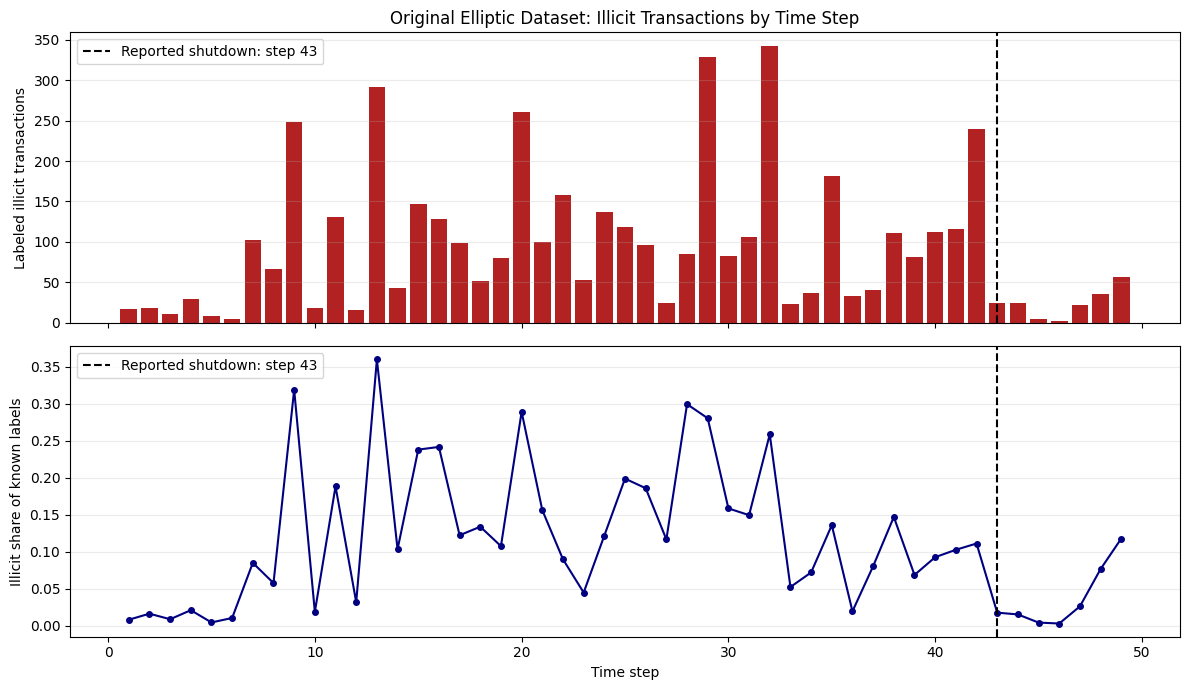

Saved plot: /content/drive/MyDrive/Colab Notebooks/AML_GNN_Project/results/real_illicit_counts_by_step.png


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True,
)

axes[0].bar(
    counts.index,
    counts["illicit"],
    color="firebrick",
)

axes[0].set_ylabel("Labeled illicit transactions")
axes[0].set_title(
    "Original Elliptic Dataset: Illicit Transactions by Time Step"
)

axes[1].plot(
    counts.index,
    counts["illicit_share_labeled"],
    marker="o",
    markersize=4,
    color="navy",
)

axes[1].set_ylabel("Illicit share of known labels")
axes[1].set_xlabel("Time step")

for ax in axes:
    ax.axvline(
        43,
        color="black",
        linestyle="--",
        label="Reported shutdown: step 43",
    )
    ax.grid(axis="y", alpha=0.25)
    ax.legend()

fig.tight_layout()

plot_path = RESULTS_DIR / "real_illicit_counts_by_step.png"

fig.savefig(
    plot_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved plot:", plot_path)

Using XGBoost:

In [ ]:
# Prepare the labeled splits
import time
import json
import platform
import xgboost as xgb

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
)

print("XGBoost version:", xgb.__version__)

assert int(xgb.__version__.split(".")[0]) >= 2, (
    "This code requires XGBoost 2 or newer."
)

train_mask = (
    nodes["time_step"].between(1, 30)
    & nodes["y"].isin([0, 1])
)

val_mask = (
    nodes["time_step"].between(31, 34)
    & nodes["y"].isin([0, 1])
)

test_mask = (
    nodes["time_step"].between(35, 49)
    & nodes["y"].isin([0, 1])
)

# Only the 93 local numerical predictors.
# Excludes IDs, time step, labels and neighborhood aggregates.
X_train = nodes.loc[train_mask, local_cols].astype("float32")
y_train = nodes.loc[train_mask, "y"].astype(int)

X_val = nodes.loc[val_mask, local_cols].astype("float32")
y_val = nodes.loc[val_mask, "y"].astype(int)

X_test = nodes.loc[test_mask, local_cols].astype("float32")
y_test = nodes.loc[test_mask, "y"].astype(int)

assert X_train.shape[1] == 93
assert y_train.nunique() == 2
assert y_val.nunique() == 2

class_weight = float(
    (y_train == 0).sum() / (y_train == 1).sum()
)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)
print("Training negative/positive ratio:", round(class_weight, 3))

XGBoost version: 3.4.1
Training shape: (26905, 93)
Validation shape: (2989, 93)
Testing shape: (16670, 93)
Training negative/positive ratio: 8.108


In [ ]:
# Train and time the frozen model
model = xgb.XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.05,
    tree_method="hist",
    device="cuda",
    scale_pos_weight=class_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=0,
    n_jobs=2,
)

# Synchronize around timing because GPU operations can be asynchronous.
torch.cuda.synchronize()
start = time.perf_counter()

model.fit(X_train, y_train)

torch.cuda.synchronize()
fit_seconds = time.perf_counter() - start

# Check the device actually selected by XGBoost.
booster_config = json.loads(model.get_booster().save_config())
actual_device = booster_config["learner"]["generic_param"]["device"]

print("XGBoost device:", actual_device)
print(f"Initial fit time: {fit_seconds:.2f} seconds")

assert actual_device.startswith("cuda"), (
    "XGBoost did not use the GPU. Send me the output."
)

# DMatrix prediction avoids CPU/GPU inplace-prediction mismatch warnings.
val_prob = model.get_booster().predict(
    xgb.DMatrix(X_val)
)

print(
    "Validation average precision:",
    round(average_precision_score(y_val, val_prob), 4),
)

XGBoost device: cuda:0
Initial fit time: 1.51 seconds
Validation average precision: 0.9634


In [ ]:
# Select the threshold using validation data only
threshold_rows = []

for threshold in np.linspace(0.05, 0.95, 19):
    predictions = (val_prob >= threshold).astype(int)

    threshold_rows.append({
        "threshold": float(threshold),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
    })

threshold_table = pd.DataFrame(threshold_rows)

# Highest validation F1; prefer the higher threshold if tied.
best_row = threshold_table.sort_values(
    ["f1", "threshold"],
    ascending=[False, False],
).iloc[0]

chosen_threshold = float(best_row["threshold"])

print("Selected threshold:", round(chosen_threshold, 3))
display(best_row.to_frame("validation_result"))

threshold_table.to_csv(
    RESULTS_DIR / "xgb_validation_thresholds.csv",
    index=False,
)

Selected threshold: 0.7


,validation_result
threshold,0.700000
precision,0.889493
recall,0.966535
f1,0.926415


In [ ]:
# Evaluate each test time step
test_prob = model.get_booster().predict(
    xgb.DMatrix(X_test)
)

test_predictions = nodes.loc[
    test_mask, ["txId", "time_step", "y"]
].copy()

test_predictions["score"] = test_prob
test_predictions["prediction"] = (
    test_prob >= chosen_threshold
).astype(int)

metric_rows = []

for step in range(35, 50):
    subset = test_predictions.loc[
        test_predictions["time_step"] == step
    ]

    if subset.empty:
        continue

    y = subset["y"].to_numpy()
    probability = subset["score"].to_numpy()
    predicted = subset["prediction"].to_numpy()

    # Review the highest-scoring 10% of known-label transactions.
    k = max(1, int(np.ceil(0.10 * len(subset))))
    order = np.argsort(-probability, kind="stable")
    top_labels = y[order[:k]]

    positives = int(y.sum())

    metric_rows.append({
        "time_step": step,
        "n_labeled": len(subset),
        "n_illicit": positives,
        "illicit_prevalence": float(y.mean()),
        "average_precision": (
            average_precision_score(y, probability)
            if len(np.unique(y)) == 2 else np.nan
        ),
        "precision": precision_score(
            y, predicted, zero_division=0
        ),
        "recall": recall_score(
            y, predicted, zero_division=0
        ),
        "f1": f1_score(
            y, predicted, zero_division=0
        ),
        "review_k": k,
        "precision_at_10pct": float(top_labels.mean()),
        "recall_at_10pct": (
            float(top_labels.sum() / positives)
            if positives > 0 else np.nan
        ),
    })

baseline_metrics = pd.DataFrame(metric_rows)

display(baseline_metrics.round(4))

baseline_metrics.to_csv(
    RESULTS_DIR / "xgb_frozen_metrics_by_step.csv",
    index=False,
)

test_predictions.to_csv(
    RESULTS_DIR / "xgb_frozen_test_predictions.csv",
    index=False,
)

model.save_model(
    str(RESULTS_DIR / "xgb_frozen_seed0.json")
)

run_info = {
    "model": "XGBoost",
    "policy": "frozen",
    "seed": 0,
    "training_steps": [1, 30],
    "validation_steps": [31, 34],
    "testing_steps": [35, 49],
    "n_predictors": len(local_cols),
    "threshold": chosen_threshold,
    "scale_pos_weight": class_weight,
    "fit_seconds": fit_seconds,
    "device": actual_device,
    "gpu": torch.cuda.get_device_name(0),
    "python": platform.python_version(),
    "xgboost": xgb.__version__,
    "parameters": model.get_params(),
}

with open(RESULTS_DIR / "xgb_frozen_run_info.json", "w") as file:
    json.dump(run_info, file, indent=2)

print("Saved model, settings, predictions and metrics.")

,time_step,n_labeled,n_illicit,illicit_prevalence,average_precision,precision,recall,f1,review_k,precision_at_10pct,recall_at_10pct
0,35,1341,182,0.1357,0.9856,0.8592,0.9725,0.9124,135,1.0000,0.7418
1,36,1708,33,0.0193,0.9623,0.3143,1.0000,0.4783,171,0.1930,1.0000
2,37,498,40,0.0803,0.7948,0.7714,0.6750,0.7200,50,0.5800,0.7250
3,38,756,111,0.1468,0.9512,0.7612,0.9189,0.8327,76,1.0000,0.6847
4,39,1183,81,0.0685,0.9337,0.5620,0.9506,0.7064,119,0.6387,0.9383
5,40,1211,112,0.0925,0.7605,0.5430,0.7321,0.6236,122,0.6393,0.6964
6,41,1132,116,0.1025,0.9638,0.6667,0.9483,0.7829,114,0.9474,0.9310
7,42,2154,239,0.1110,0.8800,0.7050,0.8201,0.7582,216,0.8843,0.7992
8,43,1370,24,0.0175,0.0370,0.0196,0.0417,0.0267,137,0.0438,0.2500
9,44,1591,24,0.0151,0.0369,0.0327,0.2083,0.0565,160,0.0312,0.2083


Saved model, settings, predictions and metrics.


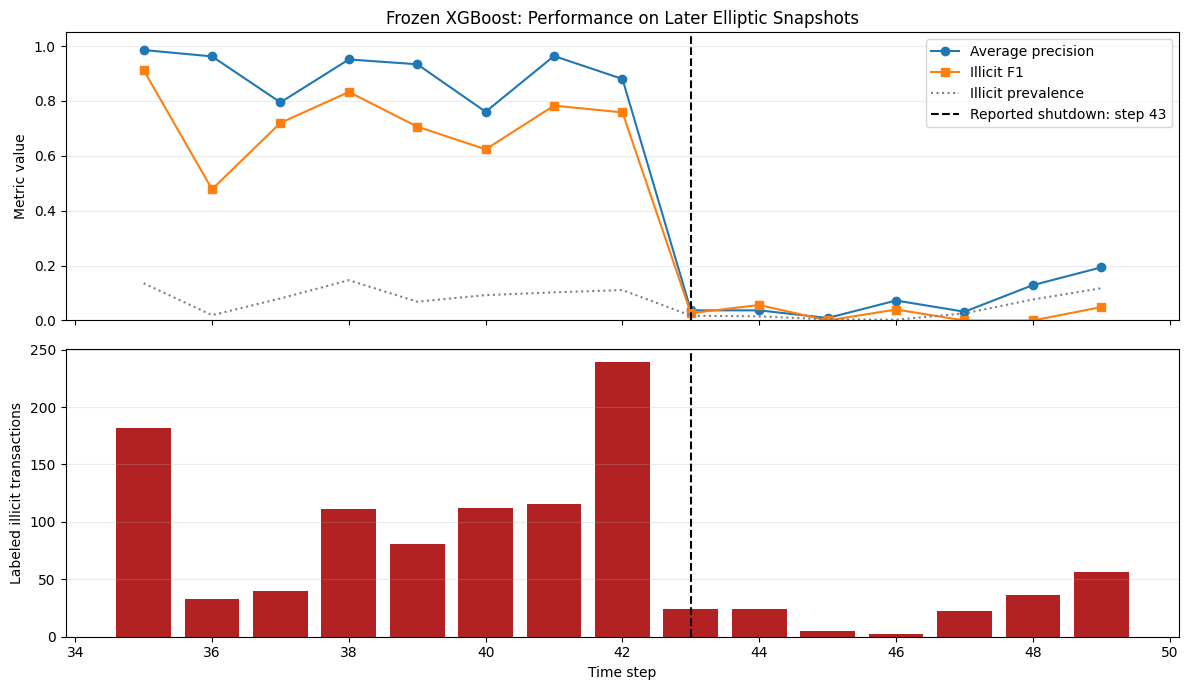

In [ ]:
# Plot performance alongside illicit counts
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True,
)

axes[0].plot(
    baseline_metrics["time_step"],
    baseline_metrics["average_precision"],
    marker="o",
    label="Average precision",
)

axes[0].plot(
    baseline_metrics["time_step"],
    baseline_metrics["f1"],
    marker="s",
    label="Illicit F1",
)

axes[0].plot(
    baseline_metrics["time_step"],
    baseline_metrics["illicit_prevalence"],
    linestyle=":",
    color="gray",
    label="Illicit prevalence",
)

axes[0].set_ylabel("Metric value")
axes[0].set_ylim(0, 1.05)
axes[0].set_title(
    "Frozen XGBoost: Performance on Later Elliptic Snapshots"
)

axes[1].bar(
    baseline_metrics["time_step"],
    baseline_metrics["n_illicit"],
    color="firebrick",
)

axes[1].set_ylabel("Labeled illicit transactions")
axes[1].set_xlabel("Time step")

for ax in axes:
    ax.axvline(
        43,
        color="black",
        linestyle="--",
        label="Reported shutdown: step 43",
    )
    ax.grid(axis="y", alpha=0.25)

axes[0].legend()
fig.tight_layout()

fig.savefig(
    RESULTS_DIR / "xgb_frozen_temporal_performance.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [ ]:
# Save the exact before-and-after summary
phase_metrics = baseline_metrics.copy()

phase_metrics["phase"] = np.select(
    [
        phase_metrics["time_step"].between(35, 42),
        phase_metrics["time_step"].eq(43),
        phase_metrics["time_step"].between(44, 49),
    ],
    ["Before: 35-42", "Transition: 43", "After: 44-49"],
    default="Other",
)

phase_summary = (
    phase_metrics.groupby("phase", sort=False)
    .agg(
        time_steps=("time_step", "count"),
        labeled_transactions=("n_labeled", "sum"),
        illicit_transactions=("n_illicit", "sum"),
        mean_AP=("average_precision", "mean"),
        mean_F1=("f1", "mean"),
        mean_recall=("recall", "mean"),
    )
    .reset_index()
)

display(phase_summary.round(4))

phase_summary.to_csv(
    RESULTS_DIR / "xgb_frozen_phase_summary.csv",
    index=False,
)

,phase,time_steps,labeled_transactions,illicit_transactions,mean_AP,mean_F1,mean_recall
0,Before: 35-42,8,9983,914,0.9040,0.7268,0.8772
1,Transition: 43,1,1370,24,0.0370,0.0267,0.0417
2,After: 44-49,6,5317,145,0.0789,0.0242,0.1240


In [ ]:
# Prepare standardized inputs
import random
import copy
import torch
from torch import nn
from sklearn.preprocessing import StandardScaler

SEED = 0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

assert torch.cuda.is_available()
device = torch.device("cuda")

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train).astype("float32")
X_val_scaled = scaler.transform(X_val).astype("float32")

assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_val_scaled).all()

X_train_tensor = torch.from_numpy(X_train_scaled).to(device)
X_val_tensor = torch.from_numpy(X_val_scaled).to(device)

y_train_tensor = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.float32,
    device=device,
)

print("Training tensor:", X_train_tensor.shape)
print("Validation tensor:", X_val_tensor.shape)
print("Device:", X_train_tensor.device)

Training tensor: torch.Size([26905, 93])
Validation tensor: torch.Size([2989, 93])
Device: cuda:0


In [ ]:
# Define the MLP
class TransactionMLP(nn.Module):
    def __init__(self, input_dim=93, hidden_dim=64, dropout=0.2):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x):
        return self.network(x).squeeze(-1)


mlp = TransactionMLP().to(device)

parameter_count = sum(
    parameter.numel()
    for parameter in mlp.parameters()
    if parameter.requires_grad
)

print(mlp)
print("Trainable parameters:", parameter_count)

TransactionMLP(
  (network): Sequential(
    (0): Linear(in_features=93, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)
Trainable parameters: 10241


In [ ]:
# Train with validation-based early stopping
loss_function = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        class_weight,
        dtype=torch.float32,
        device=device,
    )
)

optimizer = torch.optim.Adam(
    mlp.parameters(),
    lr=0.001,
    weight_decay=1e-4,
)

MAX_EPOCHS = 200
PATIENCE = 25

best_val_ap = -np.inf
best_epoch = 0
best_state = None
epochs_without_improvement = 0
training_history = []

torch.cuda.synchronize()
start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    mlp.train()

    optimizer.zero_grad(set_to_none=True)

    train_logits = mlp(X_train_tensor)
    loss = loss_function(train_logits, y_train_tensor)

    if not torch.isfinite(loss):
        raise RuntimeError("Non-finite training loss; stop and investigate.")

    loss.backward()
    optimizer.step()

    mlp.eval()

    with torch.no_grad():
        validation_scores = (
            torch.sigmoid(mlp(X_val_tensor))
            .cpu()
            .numpy()
        )

    val_ap = average_precision_score(
        y_val.to_numpy(),
        validation_scores,
    )

    training_history.append({
        "epoch": epoch,
        "training_loss": float(loss.item()),
        "validation_AP": float(val_ap),
    })

    if val_ap > best_val_ap + 1e-5:
        best_val_ap = float(val_ap)
        best_epoch = epoch
        best_state = copy.deepcopy(mlp.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Loss: {loss.item():.4f} | "
            f"Validation AP: {val_ap:.4f}"
        )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

torch.cuda.synchronize()
mlp_fit_seconds = time.perf_counter() - start

assert best_state is not None
mlp.load_state_dict(best_state)
mlp.eval()

with torch.no_grad():
    mlp_val_prob = (
        torch.sigmoid(mlp(X_val_tensor))
        .cpu()
        .numpy()
    )

history_df = pd.DataFrame(training_history)

history_df.to_csv(
    RESULTS_DIR / "mlp_seed0_training_history.csv",
    index=False,
)

print("\nBest epoch:", best_epoch)
print("Best validation AP:", round(best_val_ap, 4))
print(
    f"Training time, including validation: "
    f"{mlp_fit_seconds:.2f} seconds"
)

Epoch 001 | Loss: 1.2179 | Validation AP: 0.2580
Epoch 010 | Loss: 1.0768 | Validation AP: 0.6096
Epoch 020 | Loss: 0.9292 | Validation AP: 0.6064
Epoch 030 | Loss: 0.7872 | Validation AP: 0.6460
Epoch 040 | Loss: 0.6590 | Validation AP: 0.6811
Epoch 050 | Loss: 0.5660 | Validation AP: 0.7029
Epoch 060 | Loss: 0.4918 | Validation AP: 0.7583
Epoch 070 | Loss: 0.4529 | Validation AP: 0.7982
Epoch 080 | Loss: 0.4192 | Validation AP: 0.8249
Epoch 090 | Loss: 0.3947 | Validation AP: 0.8379
Epoch 100 | Loss: 0.3741 | Validation AP: 0.8469
Epoch 110 | Loss: 0.3620 | Validation AP: 0.8564
Epoch 120 | Loss: 0.3448 | Validation AP: 0.8596
Epoch 130 | Loss: 0.3383 | Validation AP: 0.8774
Epoch 140 | Loss: 0.3249 | Validation AP: 0.8780
Epoch 150 | Loss: 0.3237 | Validation AP: 0.8749
Epoch 160 | Loss: 0.3138 | Validation AP: 0.8744
Epoch 170 | Loss: 0.3063 | Validation AP: 0.8767
Early stopping at epoch 170.

Best epoch: 145
Best validation AP: 0.88
Training time, including validation: 1.67 secon

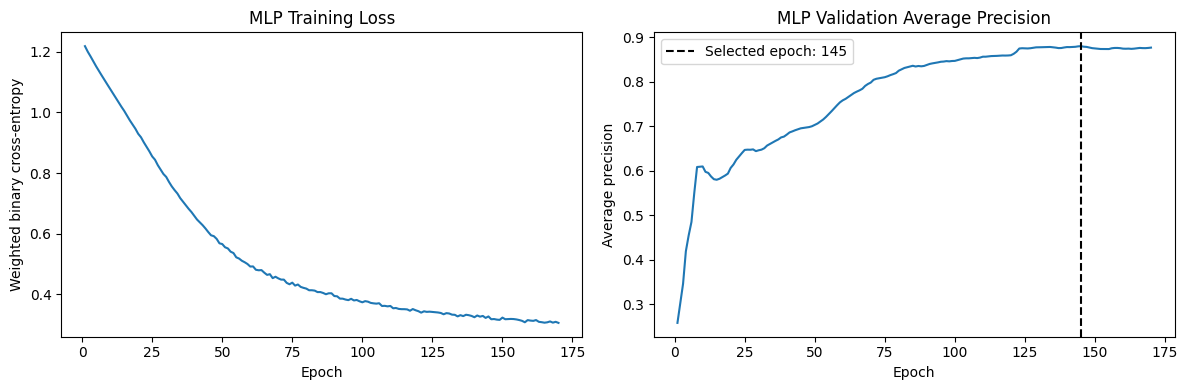

In [ ]:
# Plot the learning curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_df["epoch"],
    history_df["training_loss"],
)

axes[0].set_title("MLP Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Weighted binary cross-entropy")

axes[1].plot(
    history_df["epoch"],
    history_df["validation_AP"],
)

axes[1].axvline(
    best_epoch,
    color="black",
    linestyle="--",
    label=f"Selected epoch: {best_epoch}",
)

axes[1].set_title("MLP Validation Average Precision")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Average precision")
axes[1].legend()

fig.tight_layout()

fig.savefig(
    RESULTS_DIR / "mlp_seed0_learning_curves.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

MLP threshold:

In [ ]:
# Select the MLP threshold on validation data
mlp_threshold_rows = []

for threshold in np.linspace(0.05, 0.95, 19):
    predictions = (mlp_val_prob >= threshold).astype(int)

    mlp_threshold_rows.append({
        "threshold": float(threshold),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
    })

mlp_threshold_table = pd.DataFrame(mlp_threshold_rows)

mlp_best_row = mlp_threshold_table.sort_values(
    ["f1", "threshold"],
    ascending=[False, False],
).iloc[0]

mlp_threshold = float(mlp_best_row["threshold"])

print("Selected MLP threshold:", round(mlp_threshold, 3))
display(mlp_best_row.to_frame("validation_result"))

mlp_threshold_table.to_csv(
    RESULTS_DIR / "mlp_validation_thresholds.csv",
    index=False,
)

Selected MLP threshold: 0.8


,validation_result
threshold,0.800000
precision,0.786885
recall,0.850394
f1,0.817408


In [ ]:
# Generate frozen MLP test predictions
X_test_scaled = scaler.transform(X_test).astype("float32")

assert np.isfinite(X_test_scaled).all()

X_test_tensor = torch.from_numpy(
    X_test_scaled
).to(device)

mlp.eval()

with torch.no_grad():
    mlp_test_prob = (
        torch.sigmoid(mlp(X_test_tensor))
        .cpu()
        .numpy()
    )

assert len(mlp_test_prob) == len(y_test)
assert np.isfinite(mlp_test_prob).all()

mlp_test_predictions = nodes.loc[
    test_mask, ["txId", "time_step", "y"]
].copy()

mlp_test_predictions["score"] = mlp_test_prob
mlp_test_predictions["prediction"] = (
    mlp_test_prob >= mlp_threshold
).astype(int)

print("Test transactions scored:", len(mlp_test_predictions))

Test transactions scored: 16670


In [ ]:
# Evaluate and save the results
def evaluate_by_step(prediction_table):
    rows = []

    for step in range(35, 50):
        subset = prediction_table.loc[
            prediction_table["time_step"] == step
        ]

        if subset.empty:
            continue

        y = subset["y"].to_numpy()
        probability = subset["score"].to_numpy()
        predicted = subset["prediction"].to_numpy()

        # This evaluator expects known labels only.
        assert np.isin(y, [0, 1]).all()

        k = max(1, int(np.ceil(0.10 * len(subset))))
        order = np.argsort(-probability, kind="stable")
        top_labels = y[order[:k]]

        positives = int(y.sum())

        rows.append({
            "time_step": step,
            "n_labeled": len(subset),
            "n_illicit": positives,
            "illicit_prevalence": float(y.mean()),
            "average_precision": (
                average_precision_score(y, probability)
                if len(np.unique(y)) == 2 else np.nan
            ),
            "precision": precision_score(
                y, predicted, zero_division=0
            ),
            "recall": recall_score(
                y, predicted, zero_division=0
            ),
            "f1": f1_score(
                y, predicted, zero_division=0
            ),
            "review_k": k,
            "precision_at_10pct": float(top_labels.mean()),
            "recall_at_10pct": (
                float(top_labels.sum() / positives)
                if positives > 0 else np.nan
            ),
        })

    return pd.DataFrame(rows)


def summarize_phases(metrics):
    table = metrics.copy()

    table["phase"] = np.select(
        [
            table["time_step"].between(35, 42),
            table["time_step"].eq(43),
            table["time_step"].between(44, 49),
        ],
        ["Before: 35-42", "Transition: 43", "After: 44-49"],
        default="Other",
    )

    return (
        table.groupby("phase", sort=False)
        .agg(
            time_steps=("time_step", "count"),
            labeled_transactions=("n_labeled", "sum"),
            illicit_transactions=("n_illicit", "sum"),
            mean_AP=("average_precision", "mean"),
            mean_F1=("f1", "mean"),
            mean_recall=("recall", "mean"),
        )
        .reset_index()
    )


# Confirm both models are evaluated on identical transactions.
assert np.array_equal(
    mlp_test_predictions["txId"].to_numpy(),
    test_predictions["txId"].to_numpy(),
)

mlp_metrics = evaluate_by_step(mlp_test_predictions)
mlp_phase_summary = summarize_phases(mlp_metrics)

print("MLP METRICS BY TIME STEP")
display(mlp_metrics.round(4))

comparison = pd.concat(
    [
        summarize_phases(baseline_metrics).assign(model="XGBoost"),
        mlp_phase_summary.assign(model="MLP"),
    ],
    ignore_index=True,
)

print("FROZEN MODEL COMPARISON — SEED 0")
display(
    comparison[
        ["model", "phase", "mean_AP", "mean_F1", "mean_recall"]
    ].round(4)
)

mlp_metrics.to_csv(
    RESULTS_DIR / "mlp_frozen_metrics_by_step.csv",
    index=False,
)

mlp_test_predictions.to_csv(
    RESULTS_DIR / "mlp_frozen_test_predictions.csv",
    index=False,
)

mlp_phase_summary.to_csv(
    RESULTS_DIR / "mlp_frozen_phase_summary.csv",
    index=False,
)

comparison.to_csv(
    RESULTS_DIR / "frozen_model_phase_comparison.csv",
    index=False,
)

MLP METRICS BY TIME STEP


,time_step,n_labeled,n_illicit,illicit_prevalence,average_precision,precision,recall,f1,review_k,precision_at_10pct,recall_at_10pct
0,35,1341,182,0.1357,0.9499,0.8390,0.9451,0.8889,135,0.9852,0.7308
1,36,1708,33,0.0193,0.9227,0.2324,1.0000,0.3771,171,0.1930,1.0000
2,37,498,40,0.0803,0.5448,0.4444,0.6000,0.5106,50,0.4800,0.6000
3,38,756,111,0.1468,0.8484,0.7000,0.8829,0.7809,76,0.9605,0.6577
4,39,1183,81,0.0685,0.8212,0.4451,0.9506,0.6063,119,0.5966,0.8765
5,40,1211,112,0.0925,0.4684,0.3587,0.7143,0.4776,122,0.5738,0.6250
6,41,1132,116,0.1025,0.7219,0.4781,0.9397,0.6337,114,0.8860,0.8707
7,42,2154,239,0.1110,0.6845,0.5836,0.8033,0.6761,216,0.8380,0.7573
8,43,1370,24,0.0175,0.0147,0.0000,0.0000,0.0000,137,0.0000,0.0000
9,44,1591,24,0.0151,0.0267,0.0206,0.0833,0.0331,160,0.0188,0.1250


FROZEN MODEL COMPARISON — SEED 0


,model,phase,mean_AP,mean_F1,mean_recall
0,XGBoost,Before: 35-42,0.9040,0.7268,0.8772
1,XGBoost,Transition: 43,0.0370,0.0267,0.0417
2,XGBoost,After: 44-49,0.0789,0.0242,0.1240
3,MLP,Before: 35-42,0.7452,0.6189,0.8545
4,MLP,Transition: 43,0.0147,0.0000,0.0000
5,MLP,After: 44-49,0.0938,0.0145,0.1002


In [ ]:
# Save the MLP checkpoint and scaler
import joblib

torch.save(
    {
        "model_state_dict": {
            name: tensor.detach().cpu()
            for name, tensor in mlp.state_dict().items()
        },
        "input_dim": 93,
        "hidden_dim": 64,
        "dropout": 0.2,
        "threshold": mlp_threshold,
        "selected_epoch": int(best_epoch),
        "seed": 0,
        "feature_columns": list(local_cols),
    },
    RESULTS_DIR / "mlp_frozen_seed0.pt",
)

joblib.dump(
    scaler,
    RESULTS_DIR / "initial_training_scaler.joblib",
)

mlp_run_info = {
    "model": "MLP",
    "policy": "frozen",
    "seed": 0,
    "selected_epoch": int(best_epoch),
    "epochs_executed": len(history_df),
    "validation_AP": float(
        average_precision_score(y_val, mlp_val_prob)
    ),
    "threshold": mlp_threshold,
    "training_with_validation_seconds": mlp_fit_seconds,
    "trainable_parameters": parameter_count,
    "positive_class_weight": class_weight,
    "gpu": torch.cuda.get_device_name(0),
    "torch_version": str(torch.__version__),
}

with open(
    RESULTS_DIR / "mlp_frozen_run_info.json", "w"
) as file:
    json.dump(mlp_run_info, file, indent=2)

print("Saved MLP checkpoint, scaler and run information.")

Saved MLP checkpoint, scaler and run information.


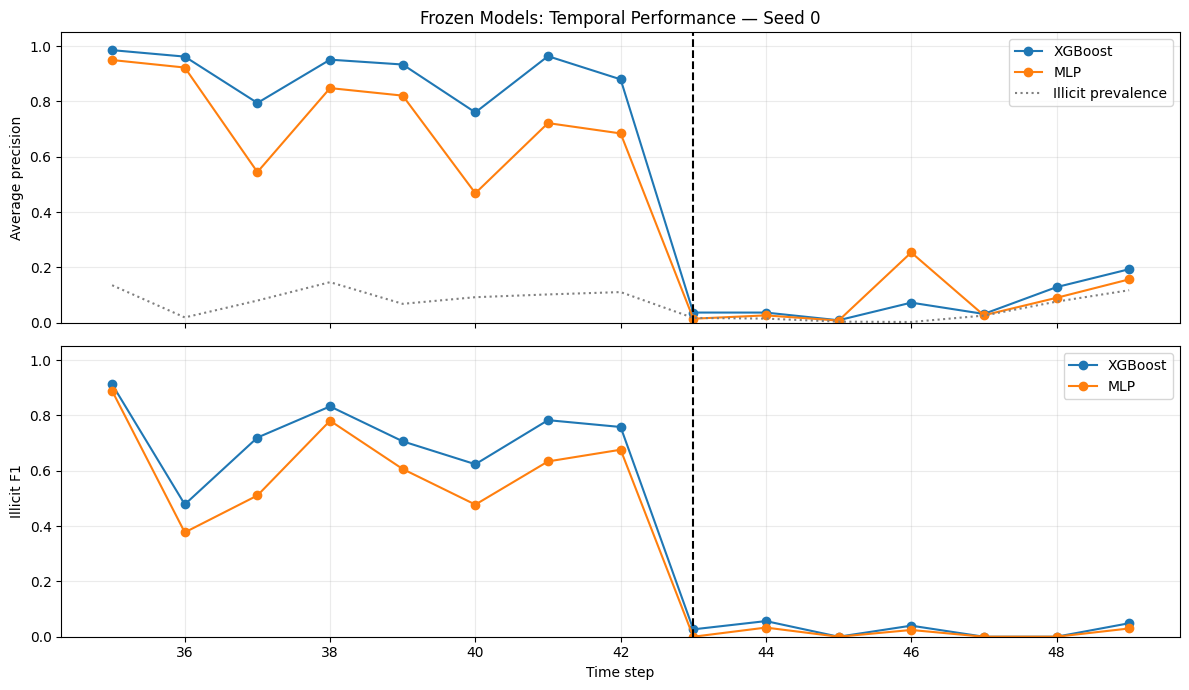

In [ ]:
# Compare the temporal performance visually
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True,
)

for name, metrics in [
    ("XGBoost", baseline_metrics),
    ("MLP", mlp_metrics),
]:
    axes[0].plot(
        metrics["time_step"],
        metrics["average_precision"],
        marker="o",
        label=name,
    )

    axes[1].plot(
        metrics["time_step"],
        metrics["f1"],
        marker="o",
        label=name,
    )

axes[0].plot(
    baseline_metrics["time_step"],
    baseline_metrics["illicit_prevalence"],
    linestyle=":",
    color="gray",
    label="Illicit prevalence",
)

axes[0].set_title("Frozen Models: Temporal Performance — Seed 0")
axes[0].set_ylabel("Average precision")
axes[1].set_ylabel("Illicit F1")
axes[1].set_xlabel("Time step")

for ax in axes:
    ax.axvline(43, color="black", linestyle="--")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend()

fig.tight_layout()

fig.savefig(
    RESULTS_DIR / "xgb_vs_mlp_frozen_temporal.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

Pytouch Geometric/GraphSAGE:

In [ ]:
import torch_geometric

from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv

print("PyTorch:", torch.__version__)
print("PyTorch Geometric:", torch_geometric.__version__)
print("GPU:", torch.cuda.get_device_name(0))

assert torch.cuda.is_available()

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PyTorch: 2.14.1+cu130
PyTorch Geometric: 2.8.1
GPU: Tesla T4


In [ ]:
# Build separate training and validation graphs
def build_graph(start_step, end_step):
    partition = nodes.loc[
        nodes["time_step"].between(start_step, end_step)
    ].copy()

    transaction_ids = partition["txId"].to_numpy()

    # Convert transaction IDs into consecutive graph-node positions.
    id_to_position = pd.Series(
        np.arange(len(partition)),
        index=transaction_ids,
    )

    edge_mask = (
        edges["txId1"].isin(transaction_ids)
        & edges["txId2"].isin(transaction_ids)
    )

    partition_edges = edges.loc[
        edge_mask, ["txId1", "txId2"]
    ]

    source = (
        partition_edges["txId1"]
        .map(id_to_position)
        .to_numpy(dtype=np.int64)
    )

    target = (
        partition_edges["txId2"]
        .map(id_to_position)
        .to_numpy(dtype=np.int64)
    )

    edge_index = torch.from_numpy(
        np.stack([source, target])
    ).long()

    # Reuse the scaler fitted on initial labeled training data.
    scaled_features = scaler.transform(
        partition[local_cols].astype("float32")
    ).astype("float32")

    assert np.isfinite(scaled_features).all()

    graph = Data(
        x=torch.from_numpy(scaled_features),
        edge_index=edge_index,
        y=torch.tensor(
            partition["y"].to_numpy(),
            dtype=torch.long,
        ),
    )

    graph.labeled_mask = graph.y >= 0

    graph.tx_id = torch.tensor(
        transaction_ids,
        dtype=torch.long,
    )

    graph.time_step = torch.tensor(
        partition["time_step"].to_numpy(),
        dtype=torch.long,
    )

    assert graph.validate(raise_on_error=True)

    # Check that every retained edge stays inside one snapshot.
    assert torch.equal(
        graph.time_step[graph.edge_index[0]],
        graph.time_step[graph.edge_index[1]],
    )

    return graph.to(device)


sage_train_graph = build_graph(1, 30)
sage_val_graph = build_graph(31, 34)

assert sage_train_graph.labeled_mask.sum().item() == len(y_train)
assert sage_val_graph.labeled_mask.sum().item() == len(y_val)

# Verify validation ordering against the existing tabular split.
assert np.array_equal(
    sage_val_graph.tx_id[
        sage_val_graph.labeled_mask
    ].cpu().numpy(),
    nodes.loc[val_mask, "txId"].to_numpy(),
)

for name, graph in [
    ("Training", sage_train_graph),
    ("Validation", sage_val_graph),
]:
    print(
        f"{name}: "
        f"{graph.num_nodes:,} total nodes | "
        f"{graph.num_edges:,} edges | "
        f"{graph.labeled_mask.sum().item():,} labeled nodes"
    )

Training: 123,287 total nodes | 142,784 edges | 26,905 labeled nodes
Validation: 12,978 total nodes | 14,059 edges | 2,989 labeled nodes


In [ ]:
# Define GraphSAGE and check its output
class TransactionGraphSAGE(nn.Module):
    def __init__(self, input_dim=93, hidden_dim=64, dropout=0.2):
        super().__init__()

        self.conv1 = SAGEConv(
            input_dim, hidden_dim, aggr="mean"
        )

        self.conv2 = SAGEConv(
            hidden_dim, hidden_dim, aggr="mean"
        )

        self.dropout = nn.Dropout(dropout)
        self.output = nn.Linear(hidden_dim, 1)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = torch.relu(x)
        x = self.dropout(x)

        x = self.conv2(x, edge_index)
        x = torch.relu(x)
        x = self.dropout(x)

        return self.output(x).squeeze(-1)


random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
torch.cuda.manual_seed_all(0)

sage_model = TransactionGraphSAGE().to(device)

sage_parameter_count = sum(
    parameter.numel()
    for parameter in sage_model.parameters()
    if parameter.requires_grad
)

sage_model.eval()

with torch.no_grad():
    check_logits = sage_model(
        sage_train_graph.x,
        sage_train_graph.edge_index,
    )

assert check_logits.shape == (sage_train_graph.num_nodes,)
assert torch.isfinite(check_logits).all()

print(sage_model)
print("Trainable parameters:", sage_parameter_count)
print("Forward-pass output shape:", check_logits.shape)
print("GraphSAGE GPU forward pass successful.")

del check_logits

TransactionGraphSAGE(
  (conv1): SAGEConv(93, 64, aggr=mean)
  (conv2): SAGEConv(64, 64, aggr=mean)
  (dropout): Dropout(p=0.2, inplace=False)
  (output): Linear(in_features=64, out_features=1, bias=True)
)
Trainable parameters: 20289
Forward-pass output shape: torch.Size([123287])
GraphSAGE GPU forward pass successful.


In [ ]:
# Train and time GraphSAGE
sage_loss_function = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        class_weight,
        dtype=torch.float32,
        device=device,
    )
)

sage_optimizer = torch.optim.Adam(
    sage_model.parameters(),
    lr=0.001,
    weight_decay=1e-4,
)

SAGE_MAX_EPOCHS = 200
SAGE_PATIENCE = 25

sage_best_val_ap = -np.inf
sage_best_epoch = 0
sage_best_state = None
sage_no_improvement = 0
sage_history = []

train_known = sage_train_graph.labeled_mask
val_known = sage_val_graph.labeled_mask

sage_val_labels = (
    sage_val_graph.y[val_known].cpu().numpy()
)

torch.cuda.synchronize()
start = time.perf_counter()

for epoch in range(1, SAGE_MAX_EPOCHS + 1):
    sage_model.train()
    sage_optimizer.zero_grad(set_to_none=True)

    logits = sage_model(
        sage_train_graph.x,
        sage_train_graph.edge_index,
    )

    # Unknown targets (-1) never enter the loss.
    loss = sage_loss_function(
        logits[train_known],
        sage_train_graph.y[train_known].float(),
    )

    if not torch.isfinite(loss):
        raise RuntimeError("Non-finite loss; stop and investigate.")

    loss.backward()
    sage_optimizer.step()

    sage_model.eval()

    with torch.no_grad():
        validation_logits = sage_model(
            sage_val_graph.x,
            sage_val_graph.edge_index,
        )

        validation_scores = (
            torch.sigmoid(validation_logits[val_known])
            .cpu()
            .numpy()
        )

    val_ap = average_precision_score(
        sage_val_labels,
        validation_scores,
    )

    sage_history.append({
        "epoch": epoch,
        "training_loss": float(loss.item()),
        "validation_AP": float(val_ap),
    })

    if val_ap > sage_best_val_ap + 1e-5:
        sage_best_val_ap = float(val_ap)
        sage_best_epoch = epoch

        sage_best_state = copy.deepcopy(
            sage_model.state_dict()
        )

        sage_no_improvement = 0

    else:
        sage_no_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Loss: {loss.item():.4f} | "
            f"Validation AP: {val_ap:.4f}"
        )

    if sage_no_improvement >= SAGE_PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

torch.cuda.synchronize()
sage_fit_seconds = time.perf_counter() - start

assert sage_best_state is not None

sage_model.load_state_dict(sage_best_state)
sage_model.eval()

sage_history_df = pd.DataFrame(sage_history)

sage_history_df.to_csv(
    RESULTS_DIR / "graphsage_seed0_training_history.csv",
    index=False,
)

# Save the selected checkpoint before continuing.
torch.save(
    {
        "model_state_dict": {
            name: tensor.detach().cpu()
            for name, tensor in sage_model.state_dict().items()
        },
        "input_dim": 93,
        "hidden_dim": 64,
        "dropout": 0.2,
        "selected_epoch": int(sage_best_epoch),
        "validation_AP": sage_best_val_ap,
        "training_with_validation_seconds": sage_fit_seconds,
        "seed": 0,
        "edge_direction": "incoming_original_directed",
        "feature_columns": list(local_cols),
    },
    RESULTS_DIR / "graphsage_selected_seed0.pt",
)

print("\nBest epoch:", sage_best_epoch)
print("Best validation AP:", round(sage_best_val_ap, 4))
print(
    f"Training time, including validation: "
    f"{sage_fit_seconds:.2f} seconds"
)
print("Saved selected GraphSAGE checkpoint.")

Epoch 001 | Loss: 1.3544 | Validation AP: 0.2230
Epoch 010 | Loss: 1.0470 | Validation AP: 0.3738
Epoch 020 | Loss: 0.8848 | Validation AP: 0.3682
Epoch 030 | Loss: 0.7539 | Validation AP: 0.4513
Epoch 040 | Loss: 0.6382 | Validation AP: 0.5786
Epoch 050 | Loss: 0.5481 | Validation AP: 0.7024
Epoch 060 | Loss: 0.4839 | Validation AP: 0.7791
Epoch 070 | Loss: 0.4319 | Validation AP: 0.8115
Epoch 080 | Loss: 0.3968 | Validation AP: 0.7365
Epoch 090 | Loss: 0.3666 | Validation AP: 0.7236
Early stopping at epoch 98.

Best epoch: 73
Best validation AP: 0.8164
Training time, including validation: 2.11 seconds
Saved selected GraphSAGE checkpoint.


After GraphSAGE trained successfully, It's time to select the threshold.

In [ ]:
# Select the GraphSAGE threshold
sage_model.eval()

with torch.no_grad():
    sage_val_prob = (
        torch.sigmoid(
            sage_model(
                sage_val_graph.x,
                sage_val_graph.edge_index,
            )[sage_val_graph.labeled_mask]
        )
        .cpu()
        .numpy()
    )

sage_threshold_rows = []

for threshold in np.linspace(0.05, 0.95, 19):
    predictions = (sage_val_prob >= threshold).astype(int)

    sage_threshold_rows.append({
        "threshold": float(threshold),
        "precision": precision_score(
            sage_val_labels, predictions, zero_division=0
        ),
        "recall": recall_score(
            sage_val_labels, predictions, zero_division=0
        ),
        "f1": f1_score(
            sage_val_labels, predictions, zero_division=0
        ),
    })

sage_threshold_table = pd.DataFrame(sage_threshold_rows)

sage_best_row = sage_threshold_table.sort_values(
    ["f1", "threshold"],
    ascending=[False, False],
).iloc[0]

sage_threshold = float(sage_best_row["threshold"])

print("Selected GraphSAGE threshold:", round(sage_threshold, 3))
display(sage_best_row.to_frame("validation_result"))

sage_threshold_table.to_csv(
    RESULTS_DIR / "graphsage_validation_thresholds.csv",
    index=False,
)

Selected GraphSAGE threshold: 0.85


,validation_result
threshold,0.850000
precision,0.782689
recall,0.836614
f1,0.808754


In [ ]:
# Build the test graph and generate predictions
sage_test_graph = build_graph(35, 49)
test_known = sage_test_graph.labeled_mask

print("Total test nodes:", sage_test_graph.num_nodes)
print("Total test edges:", sage_test_graph.num_edges)
print("Labeled test nodes:", test_known.sum().item())

# Verify identical transaction ordering across models.
sage_test_ids = (
    sage_test_graph.tx_id[test_known].cpu().numpy()
)

assert np.array_equal(
    sage_test_ids,
    test_predictions["txId"].to_numpy(),
)

sage_model.eval()

with torch.no_grad():
    sage_test_prob = (
        torch.sigmoid(
            sage_model(
                sage_test_graph.x,
                sage_test_graph.edge_index,
            )[test_known]
        )
        .cpu()
        .numpy()
    )

assert np.isfinite(sage_test_prob).all()
assert len(sage_test_prob) == 16670

sage_test_predictions = pd.DataFrame({
    "txId": sage_test_ids,
    "time_step": (
        sage_test_graph.time_step[test_known].cpu().numpy()
    ),
    "y": sage_test_graph.y[test_known].cpu().numpy(),
    "score": sage_test_prob,
    "prediction": (
        sage_test_prob >= sage_threshold
    ).astype(int),
})

assert np.array_equal(
    sage_test_predictions["y"].to_numpy(),
    test_predictions["y"].to_numpy(),
)

print("GraphSAGE test transactions scored:", len(sage_test_predictions))

Total test nodes: 67504
Total test edges: 77512
Labeled test nodes: 16670
GraphSAGE test transactions scored: 16670


In [ ]:
# Evaluate and compare all three models
sage_metrics = evaluate_by_step(sage_test_predictions)
sage_phase_summary = summarize_phases(sage_metrics)

print("GRAPHSAGE METRICS BY TIME STEP")
display(sage_metrics.round(4))

all_frozen_comparison = pd.concat(
    [
        summarize_phases(baseline_metrics).assign(model="XGBoost"),
        summarize_phases(mlp_metrics).assign(model="MLP"),
        sage_phase_summary.assign(model="GraphSAGE"),
    ],
    ignore_index=True,
)

print("ALL FROZEN MODELS — SEED 0")
display(
    all_frozen_comparison[
        [
            "model",
            "phase",
            "illicit_transactions",
            "mean_AP",
            "mean_F1",
            "mean_recall",
        ]
    ].round(4)
)

sage_metrics.to_csv(
    RESULTS_DIR / "graphsage_frozen_metrics_by_step.csv",
    index=False,
)

sage_phase_summary.to_csv(
    RESULTS_DIR / "graphsage_frozen_phase_summary.csv",
    index=False,
)

sage_test_predictions.to_csv(
    RESULTS_DIR / "graphsage_frozen_test_predictions.csv",
    index=False,
)

all_frozen_comparison.to_csv(
    RESULTS_DIR / "all_frozen_models_phase_comparison.csv",
    index=False,
)

GRAPHSAGE METRICS BY TIME STEP


,time_step,n_labeled,n_illicit,illicit_prevalence,average_precision,precision,recall,f1,review_k,precision_at_10pct,recall_at_10pct
0,35,1341,182,0.1357,0.9003,0.8211,0.8571,0.8387,135,0.8815,0.6538
1,36,1708,33,0.0193,0.5621,0.3966,0.6970,0.5055,171,0.1462,0.7576
2,37,498,40,0.0803,0.6126,0.7407,0.5000,0.5970,50,0.4400,0.5500
3,38,756,111,0.1468,0.7408,0.7442,0.5766,0.6497,76,0.7632,0.5225
4,39,1183,81,0.0685,0.6468,0.6970,0.5679,0.6259,119,0.4874,0.7160
5,40,1211,112,0.0925,0.5907,0.6333,0.5089,0.5644,122,0.5492,0.5982
6,41,1132,116,0.1025,0.6875,0.6436,0.5603,0.5991,114,0.6053,0.5948
7,42,2154,239,0.1110,0.8171,0.7956,0.7490,0.7716,216,0.8194,0.7406
8,43,1370,24,0.0175,0.0315,0.0000,0.0000,0.0000,137,0.0219,0.1250
9,44,1591,24,0.0151,0.0161,0.0118,0.0417,0.0183,160,0.0062,0.0417


ALL FROZEN MODELS — SEED 0


,model,phase,illicit_transactions,mean_AP,mean_F1,mean_recall
0,XGBoost,Before: 35-42,914,0.9040,0.7268,0.8772
1,XGBoost,Transition: 43,24,0.0370,0.0267,0.0417
2,XGBoost,After: 44-49,145,0.0789,0.0242,0.1240
3,MLP,Before: 35-42,914,0.7452,0.6189,0.8545
4,MLP,Transition: 43,24,0.0147,0.0000,0.0000
5,MLP,After: 44-49,145,0.0938,0.0145,0.1002
6,GraphSAGE,Before: 35-42,914,0.6947,0.6440,0.6271
7,GraphSAGE,Transition: 43,24,0.0315,0.0000,0.0000
8,GraphSAGE,After: 44-49,145,0.0716,0.0129,0.0145


In [ ]:
# Save the complete frozen GraphSAGE checkpoint
torch.save(
    {
        "model_state_dict": {
            name: tensor.detach().cpu()
            for name, tensor in sage_model.state_dict().items()
        },
        "input_dim": 93,
        "hidden_dim": 64,
        "dropout": 0.2,
        "threshold": sage_threshold,
        "selected_epoch": int(sage_best_epoch),
        "seed": 0,
        "edge_direction": "incoming_original_directed",
        "feature_columns": list(local_cols),
    },
    RESULTS_DIR / "graphsage_frozen_seed0.pt",
)

sage_run_info = {
    "model": "GraphSAGE",
    "policy": "frozen",
    "seed": 0,
    "selected_epoch": int(sage_best_epoch),
    "epochs_executed": len(sage_history_df),
    "validation_AP": float(
        average_precision_score(sage_val_labels, sage_val_prob)
    ),
    "threshold": sage_threshold,
    "training_with_validation_seconds": sage_fit_seconds,
    "trainable_parameters": sage_parameter_count,
    "positive_class_weight": class_weight,
    "training_steps": [1, 30],
    "validation_steps": [31, 34],
    "testing_steps": [35, 49],
    "edge_direction": "incoming_original_directed",
    "gpu": torch.cuda.get_device_name(0),
    "torch_version": str(torch.__version__),
    "pyg_version": str(torch_geometric.__version__),
}

with open(
    RESULTS_DIR / "graphsage_frozen_run_info.json", "w"
) as file:
    json.dump(sage_run_info, file, indent=2)

print("Saved GraphSAGE checkpoint and run information.")

Saved GraphSAGE checkpoint and run information.


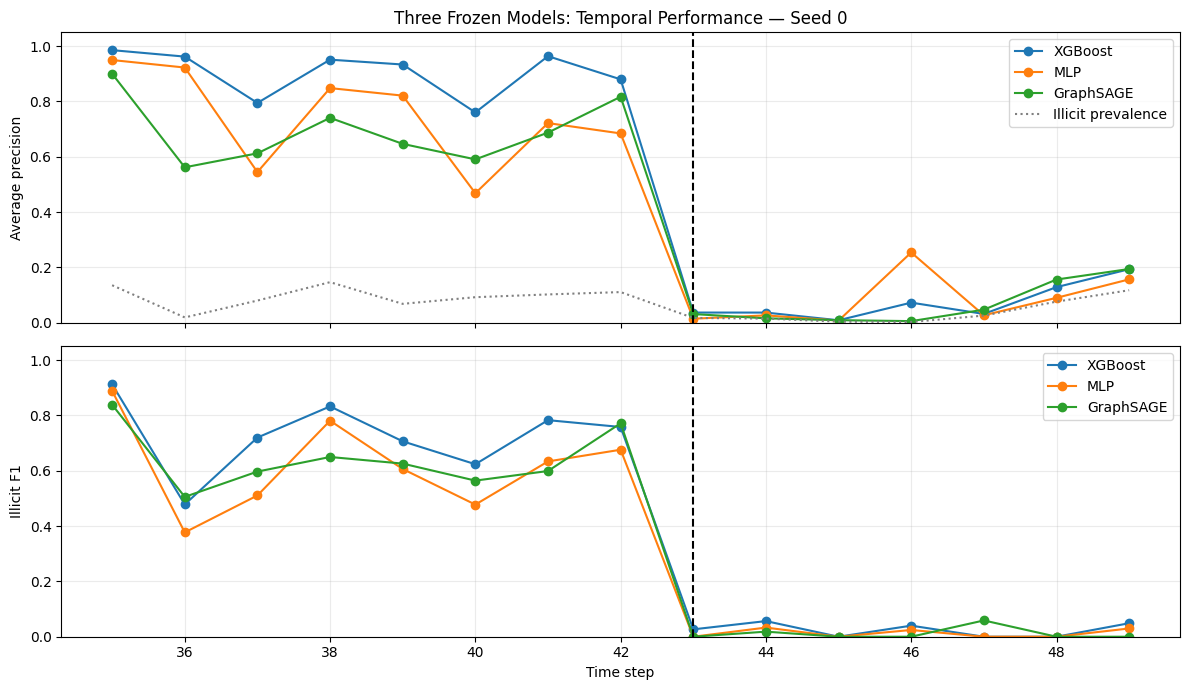

In [ ]:
# Plot all three frozen models
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True,
)

for name, metrics in [
    ("XGBoost", baseline_metrics),
    ("MLP", mlp_metrics),
    ("GraphSAGE", sage_metrics),
]:
    axes[0].plot(
        metrics["time_step"],
        metrics["average_precision"],
        marker="o",
        label=name,
    )

    axes[1].plot(
        metrics["time_step"],
        metrics["f1"],
        marker="o",
        label=name,
    )

axes[0].plot(
    baseline_metrics["time_step"],
    baseline_metrics["illicit_prevalence"],
    linestyle=":",
    color="gray",
    label="Illicit prevalence",
)

axes[0].set_title("Three Frozen Models: Temporal Performance — Seed 0")
axes[0].set_ylabel("Average precision")
axes[1].set_ylabel("Illicit F1")
axes[1].set_xlabel("Time step")

for ax in axes:
    ax.axvline(43, color="black", linestyle="--")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend()

fig.tight_layout()

fig.savefig(
    RESULTS_DIR / "three_frozen_models_temporal.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

The main research question now is whether adaptation changes these results differently across model families.

In [ ]:
ADAPTATION_POLICIES = ["expanding", "rolling", "recency"]

ROLLING_WINDOW = 8
RECENCY_HALF_LIFE = 4
ADAPTATION_SEED = 0

# Lock these to the initial training/validation choices.
XGB_FIXED_THRESHOLD = float(chosen_threshold)
FIXED_CLASS_WEIGHT = float(class_weight)

print("Frozen XGBoost threshold:", XGB_FIXED_THRESHOLD)
print("Fixed positive-class weight:", round(FIXED_CLASS_WEIGHT, 3))

assert np.isclose(XGB_FIXED_THRESHOLD, 0.70)

Frozen XGBoost threshold: 0.7
Fixed positive-class weight: 8.108


In [ ]:
# Define past-only training selection
def select_adaptation_training(score_step, policy):
    times = nodes["time_step"]

    eligible = (
        (times < score_step)
        & nodes["y"].isin([0, 1])
    )

    if policy == "rolling":
        eligible &= times >= score_step - ROLLING_WINDOW

    elif policy not in {"expanding", "recency"}:
        raise ValueError(f"Unknown policy: {policy}")

    training_rows = nodes.loc[eligible].copy()

    assert not training_rows.empty
    assert training_rows["time_step"].max() < score_step
    assert training_rows["y"].isin([0, 1]).all()

    if training_rows["y"].nunique() != 2:
        raise ValueError(
            f"{policy}, step {score_step}: "
            "training history does not contain both classes."
        )

    weights = np.ones(len(training_rows), dtype=np.float32)

    if policy == "recency":
        age = (
            (score_step - 1)
            - training_rows["time_step"].to_numpy()
        )

        weights = np.exp2(
            -age / RECENCY_HALF_LIFE
        ).astype(np.float32)

        weights /= weights.mean()

    assert np.isfinite(weights).all()
    assert (weights > 0).all()

    return training_rows, weights


# Check the history boundaries without training anything.
history_checks = []

for policy in ADAPTATION_POLICIES:
    rows, weights = select_adaptation_training(44, policy)

    history_checks.append({
        "policy": policy,
        "scoring_step": 44,
        "earliest_training_step": int(rows["time_step"].min()),
        "latest_training_step": int(rows["time_step"].max()),
        "labeled_training_rows": len(rows),
        "illicit_training_rows": int(rows["y"].sum()),
        "mean_sample_weight": float(weights.mean()),
    })

display(pd.DataFrame(history_checks))

,policy,scoring_step,earliest_training_step,latest_training_step,labeled_training_rows,illicit_training_rows,mean_sample_weight
0,expanding,44,1,43,41247,4400,1.0
1,rolling,44,36,43,10012,756,1.0
2,recency,44,1,43,41247,4400,1.0


XGBOOST adaptation:


In [ ]:
# Run the XGBoost adaptation experiment
xgb_adaptation_rows = []
xgb_adaptation_predictions = []
xgb_adaptation_timing = []

adaptation_start = time.perf_counter()

for policy in ADAPTATION_POLICIES:
    print(f"\nPOLICY: {policy.upper()}")

    for score_step in range(35, 50):
        training_rows, sample_weights = (
            select_adaptation_training(score_step, policy)
        )

        score_rows = nodes.loc[
            nodes["time_step"].eq(score_step)
            & nodes["y"].isin([0, 1])
        ].copy()

        assert not score_rows.empty

        current_model = xgb.XGBClassifier(
            n_estimators=150,
            max_depth=4,
            learning_rate=0.05,
            tree_method="hist",
            device="cuda",
            scale_pos_weight=FIXED_CLASS_WEIGHT,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=ADAPTATION_SEED,
            n_jobs=2,
        )

        torch.cuda.synchronize()
        fit_start = time.perf_counter()

        current_model.fit(
            training_rows[local_cols].astype("float32"),
            training_rows["y"].astype(int),
            sample_weight=sample_weights,
        )

        torch.cuda.synchronize()
        refit_seconds = time.perf_counter() - fit_start

        # Predict before using this step's labels for evaluation.
        scores = current_model.get_booster().predict(
            xgb.DMatrix(
                score_rows[local_cols].astype("float32")
            )
        )

        assert np.isfinite(scores).all()

        step_predictions = score_rows[
            ["txId", "time_step", "y"]
        ].copy()

        step_predictions["score"] = scores
        step_predictions["prediction"] = (
            scores >= XGB_FIXED_THRESHOLD
        ).astype(int)

        # Current labels enter evaluation, never this fit's training.
        step_metrics = evaluate_by_step(step_predictions)

        assert len(step_metrics) == 1

        step_metrics["model"] = "XGBoost"
        step_metrics["policy"] = policy
        step_metrics["seed"] = ADAPTATION_SEED

        step_predictions["model"] = "XGBoost"
        step_predictions["policy"] = policy
        step_predictions["seed"] = ADAPTATION_SEED

        xgb_adaptation_rows.append(step_metrics)
        xgb_adaptation_predictions.append(step_predictions)

        xgb_adaptation_timing.append({
            "model": "XGBoost",
            "policy": policy,
            "seed": ADAPTATION_SEED,
            "score_step": score_step,
            "training_start": int(
                training_rows["time_step"].min()
            ),
            "training_end": int(
                training_rows["time_step"].max()
            ),
            "n_training_labeled": len(training_rows),
            "n_training_illicit": int(training_rows["y"].sum()),
            "refit_seconds": refit_seconds,
        })

        # Save progress.
        pd.concat(
            xgb_adaptation_rows, ignore_index=True
        ).to_csv(
            RESULTS_DIR / "xgb_adaptation_seed0_metrics.csv",
            index=False,
        )

        pd.concat(
            xgb_adaptation_predictions, ignore_index=True
        ).to_csv(
            RESULTS_DIR / "xgb_adaptation_seed0_predictions.csv",
            index=False,
        )

        pd.DataFrame(xgb_adaptation_timing).to_csv(
            RESULTS_DIR / "xgb_adaptation_seed0_timing.csv",
            index=False,
        )

        result = step_metrics.iloc[0]

        print(
            f"Step {score_step:02d} | "
            f"Train through {score_step - 1:02d} | "
            f"AP {result['average_precision']:.4f} | "
            f"F1 {result['f1']:.4f} | "
            f"Fit {refit_seconds:.2f}s"
        )

        del current_model

print(
    "\nTotal experiment time:",
    round(time.perf_counter() - adaptation_start, 2),
    "seconds",
)


POLICY: EXPANDING
Step 35 | Train through 34 | AP 0.9856 | F1 0.9143 | Fit 1.66s
Step 36 | Train through 35 | AP 0.9946 | F1 0.5593 | Fit 1.60s
Step 37 | Train through 36 | AP 0.8489 | F1 0.7778 | Fit 0.89s
Step 38 | Train through 37 | AP 0.9618 | F1 0.9266 | Fit 0.92s
Step 39 | Train through 38 | AP 0.9547 | F1 0.8916 | Fit 0.72s
Step 40 | Train through 39 | AP 0.7667 | F1 0.7070 | Fit 1.05s
Step 41 | Train through 40 | AP 0.9677 | F1 0.9237 | Fit 0.98s
Step 42 | Train through 41 | AP 0.8978 | F1 0.8186 | Fit 1.09s
Step 43 | Train through 42 | AP 0.0645 | F1 0.0000 | Fit 1.02s
Step 44 | Train through 43 | AP 0.1082 | F1 0.1633 | Fit 1.02s
Step 45 | Train through 44 | AP 0.0348 | F1 0.0769 | Fit 1.81s
Step 46 | Train through 45 | AP 0.2585 | F1 0.2222 | Fit 2.47s
Step 47 | Train through 46 | AP 0.0663 | F1 0.0000 | Fit 1.32s
Step 48 | Train through 47 | AP 0.2588 | F1 0.0000 | Fit 0.91s
Step 49 | Train through 48 | AP 0.4631 | F1 0.0606 | Fit 0.89s

POLICY: ROLLING
Step 35 | Train thr

In [ ]:
# Compare adaptation policies against expanding history
xgb_adaptation_metrics = pd.concat(
    xgb_adaptation_rows,
    ignore_index=True,
)

frozen_reference = baseline_metrics.copy()
frozen_reference["model"] = "XGBoost"
frozen_reference["policy"] = "frozen"
frozen_reference["seed"] = 0

xgb_policy_metrics = pd.concat(
    [frozen_reference, xgb_adaptation_metrics],
    ignore_index=True,
)

summary_parts = []

for policy, metrics in xgb_policy_metrics.groupby(
    "policy", sort=False
):
    summary = summarize_phases(metrics)
    summary["policy"] = policy
    summary_parts.append(summary)

xgb_policy_summary = pd.concat(
    summary_parts, ignore_index=True
)

print("XGBOOST POLICY COMPARISON — SEED 0")

display(
    xgb_policy_summary[
        ["policy", "phase", "mean_AP", "mean_F1", "mean_recall"]
    ].round(4)
)

post_shift = (
    xgb_policy_summary.loc[
        xgb_policy_summary["phase"].eq("After: 44-49")
    ]
    .set_index("policy")
    .copy()
)

post_shift["AP_difference_vs_expanding"] = (
    post_shift["mean_AP"]
    - post_shift.loc["expanding", "mean_AP"]
)

print("POST-SHIFT RESULTS")
display(
    post_shift[
        ["mean_AP", "mean_F1", "AP_difference_vs_expanding"]
    ].round(4)
)

xgb_policy_summary.to_csv(
    RESULTS_DIR / "xgb_policy_phase_summary_seed0.csv",
    index=False,
)

XGBOOST POLICY COMPARISON — SEED 0


,policy,phase,mean_AP,mean_F1,mean_recall
0,frozen,Before: 35-42,0.9040,0.7268,0.8772
1,frozen,Transition: 43,0.0370,0.0267,0.0417
2,frozen,After: 44-49,0.0789,0.0242,0.1240
3,expanding,Before: 35-42,0.9222,0.8149,0.8651
4,expanding,Transition: 43,0.0645,0.0000,0.0000
5,expanding,After: 44-49,0.1983,0.0872,0.1504
6,rolling,Before: 35-42,0.9306,0.8797,0.8311
7,rolling,Transition: 43,0.2164,0.0741,0.0417
8,rolling,After: 44-49,0.3164,0.2120,0.1739
9,recency,Before: 35-42,0.9327,0.8834,0.8346


POST-SHIFT RESULTS


,mean_AP,mean_F1,AP_difference_vs_expanding
policy,,,
frozen,0.0789,0.0242,-0.1194
expanding,0.1983,0.0872,0.0000
rolling,0.3164,0.2120,0.1182
recency,0.4053,0.2685,0.2070


MLP adaptation:

In [ ]:
# Lock the MLP adaptation settings
with open(
    RESULTS_DIR / "mlp_frozen_run_info.json"
) as file:
    mlp_initial_settings = json.load(file)

MLP_FIXED_THRESHOLD = float(
    mlp_initial_settings["threshold"]
)

MLP_ADAPT_EPOCHS = int(
    mlp_initial_settings["selected_epoch"]
)

assert np.isclose(MLP_FIXED_THRESHOLD, 0.80)
assert MLP_ADAPT_EPOCHS == 145

print("Fixed MLP threshold:", MLP_FIXED_THRESHOLD)
print("Epochs per refit:", MLP_ADAPT_EPOCHS)
print("Positive-class weight:", FIXED_CLASS_WEIGHT)

Fixed MLP threshold: 0.7999999999999999
Epochs per refit: 145
Positive-class weight: 8.107989167230873


In [ ]:
# Run MLP adaptation
mlp_adaptation_rows = []
mlp_adaptation_predictions = []
mlp_adaptation_timing = []

mlp_adaptation_start = time.perf_counter()

for policy in ADAPTATION_POLICIES:
    print(f"\nPOLICY: {policy.upper()}")

    for score_step in range(35, 50):
        training_rows, sample_weights = (
            select_adaptation_training(score_step, policy)
        )

        score_rows = nodes.loc[
            nodes["time_step"].eq(score_step)
            & nodes["y"].isin([0, 1])
        ].copy()

        assert not score_rows.empty
        assert training_rows["time_step"].max() < score_step

        # The original training-fitted scaler remains fixed.
        train_array = scaler.transform(
            training_rows[local_cols].astype("float32")
        ).astype("float32")

        score_array = scaler.transform(
            score_rows[local_cols].astype("float32")
        ).astype("float32")

        assert np.isfinite(train_array).all()
        assert np.isfinite(score_array).all()

        train_x = torch.from_numpy(train_array).to(device)

        train_y = torch.tensor(
            training_rows["y"].to_numpy(),
            dtype=torch.float32,
            device=device,
        )

        train_weights = torch.tensor(
            sample_weights,
            dtype=torch.float32,
            device=device,
        )

        score_x = torch.from_numpy(score_array).to(device)

        # Reinitialize from scratch for every policy and step.
        random.seed(ADAPTATION_SEED)
        np.random.seed(ADAPTATION_SEED)
        torch.manual_seed(ADAPTATION_SEED)
        torch.cuda.manual_seed_all(ADAPTATION_SEED)

        current_mlp = TransactionMLP().to(device)

        current_optimizer = torch.optim.Adam(
            current_mlp.parameters(),
            lr=0.001,
            weight_decay=1e-4,
        )

        per_transaction_loss = nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(
                FIXED_CLASS_WEIGHT,
                dtype=torch.float32,
                device=device,
            ),
            reduction="none",
        )

        torch.cuda.synchronize()
        fit_start = time.perf_counter()

        # Fixed epoch budget: no current-step validation or early stopping.
        for epoch in range(MLP_ADAPT_EPOCHS):
            current_mlp.train()
            current_optimizer.zero_grad(set_to_none=True)

            logits = current_mlp(train_x)

            individual_losses = per_transaction_loss(
                logits, train_y
            )

            loss = (
                individual_losses * train_weights
            ).sum() / train_weights.sum()

            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite loss: {policy}, step {score_step}"
                )

            loss.backward()
            current_optimizer.step()

        torch.cuda.synchronize()
        refit_seconds = time.perf_counter() - fit_start

        current_mlp.eval()

        with torch.no_grad():
            scores = (
                torch.sigmoid(current_mlp(score_x))
                .cpu()
                .numpy()
            )

        assert np.isfinite(scores).all()

        # Current-step labels are used only after prediction.
        step_predictions = score_rows[
            ["txId", "time_step", "y"]
        ].copy()

        step_predictions["score"] = scores
        step_predictions["prediction"] = (
            scores >= MLP_FIXED_THRESHOLD
        ).astype(int)

        step_metrics = evaluate_by_step(step_predictions)
        assert len(step_metrics) == 1

        step_metrics["model"] = "MLP"
        step_metrics["policy"] = policy
        step_metrics["seed"] = ADAPTATION_SEED

        step_predictions["model"] = "MLP"
        step_predictions["policy"] = policy
        step_predictions["seed"] = ADAPTATION_SEED

        mlp_adaptation_rows.append(step_metrics)
        mlp_adaptation_predictions.append(step_predictions)

        mlp_adaptation_timing.append({
            "model": "MLP",
            "policy": policy,
            "seed": ADAPTATION_SEED,
            "score_step": score_step,
            "training_start": int(
                training_rows["time_step"].min()
            ),
            "training_end": int(
                training_rows["time_step"].max()
            ),
            "n_training_labeled": len(training_rows),
            "n_training_illicit": int(training_rows["y"].sum()),
            "epochs": MLP_ADAPT_EPOCHS,
            "refit_seconds": refit_seconds,
        })

        # Save progress after each completed refit.
        pd.concat(
            mlp_adaptation_rows, ignore_index=True
        ).to_csv(
            RESULTS_DIR / "mlp_adaptation_seed0_metrics.csv",
            index=False,
        )

        pd.concat(
            mlp_adaptation_predictions, ignore_index=True
        ).to_csv(
            RESULTS_DIR / "mlp_adaptation_seed0_predictions.csv",
            index=False,
        )

        pd.DataFrame(mlp_adaptation_timing).to_csv(
            RESULTS_DIR / "mlp_adaptation_seed0_timing.csv",
            index=False,
        )

        result = step_metrics.iloc[0]

        print(
            f"Step {score_step:02d} | "
            f"AP {result['average_precision']:.4f} | "
            f"F1 {result['f1']:.4f} | "
            f"Fit {refit_seconds:.2f}s"
        )

        del (
            current_mlp,
            current_optimizer,
            train_x,
            train_y,
            train_weights,
            score_x,
            logits,
            individual_losses,
            loss,
        )

mlp_total_adaptation_seconds = (
    time.perf_counter() - mlp_adaptation_start
)

print(
    "\nTotal MLP adaptation experiment time:",
    round(mlp_total_adaptation_seconds, 2),
    "seconds",
)


POLICY: EXPANDING
Step 35 | AP 0.9522 | F1 0.9010 | Fit 0.75s
Step 36 | AP 0.9146 | F1 0.7021 | Fit 0.71s
Step 37 | AP 0.6976 | F1 0.6857 | Fit 0.48s
Step 38 | AP 0.8693 | F1 0.8767 | Fit 0.46s
Step 39 | AP 0.9498 | F1 0.8876 | Fit 0.49s
Step 40 | AP 0.6935 | F1 0.6837 | Fit 0.48s
Step 41 | AP 0.8247 | F1 0.8957 | Fit 0.52s
Step 42 | AP 0.8681 | F1 0.8406 | Fit 0.54s
Step 43 | AP 0.0355 | F1 0.0000 | Fit 0.53s
Step 44 | AP 0.0395 | F1 0.0444 | Fit 0.59s
Step 45 | AP 0.0125 | F1 0.0000 | Fit 0.47s
Step 46 | AP 0.0037 | F1 0.0000 | Fit 0.46s
Step 47 | AP 0.0423 | F1 0.0000 | Fit 0.53s
Step 48 | AP 0.1167 | F1 0.0000 | Fit 0.51s
Step 49 | AP 0.1959 | F1 0.0345 | Fit 0.58s

POLICY: ROLLING
Step 35 | AP 0.9063 | F1 0.9072 | Fit 0.58s
Step 36 | AP 0.8448 | F1 0.7294 | Fit 0.65s
Step 37 | AP 0.7446 | F1 0.6866 | Fit 0.66s
Step 38 | AP 0.8790 | F1 0.8676 | Fit 0.84s
Step 39 | AP 0.9518 | F1 0.8903 | Fit 0.46s
Step 40 | AP 0.7095 | F1 0.6381 | Fit 0.45s
Step 41 | AP 0.9492 | F1 0.8670 | Fit 0.

In [ ]:
# Summarize the MLP policies
mlp_adaptation_metrics = pd.concat(
    mlp_adaptation_rows,
    ignore_index=True,
)

mlp_frozen_reference = mlp_metrics.copy()
mlp_frozen_reference["model"] = "MLP"
mlp_frozen_reference["policy"] = "frozen"
mlp_frozen_reference["seed"] = 0

mlp_policy_metrics = pd.concat(
    [mlp_frozen_reference, mlp_adaptation_metrics],
    ignore_index=True,
)

mlp_summary_parts = []

for policy, metrics in mlp_policy_metrics.groupby(
    "policy", sort=False
):
    summary = summarize_phases(metrics)
    summary["policy"] = policy
    mlp_summary_parts.append(summary)

mlp_policy_summary = pd.concat(
    mlp_summary_parts,
    ignore_index=True,
)

print("MLP POLICY COMPARISON — SEED 0")

display(
    mlp_policy_summary[
        ["policy", "phase", "mean_AP", "mean_F1", "mean_recall"]
    ].round(4)
)

mlp_policy_summary.to_csv(
    RESULTS_DIR / "mlp_policy_phase_summary_seed0.csv",
    index=False,
)

MLP POLICY COMPARISON — SEED 0


,policy,phase,mean_AP,mean_F1,mean_recall
0,frozen,Before: 35-42,0.7452,0.6189,0.8545
1,frozen,Transition: 43,0.0147,0.0000,0.0000
2,frozen,After: 44-49,0.0938,0.0145,0.1002
3,expanding,Before: 35-42,0.8462,0.8091,0.8236
4,expanding,Transition: 43,0.0355,0.0000,0.0000
5,expanding,After: 44-49,0.0684,0.0132,0.0099
6,rolling,Before: 35-42,0.8577,0.8018,0.7974
7,rolling,Transition: 43,0.0661,0.0000,0.0000
8,rolling,After: 44-49,0.1179,0.0205,0.0106
9,recency,Before: 35-42,0.8404,0.8107,0.8044


In [ ]:
# Compare adaptation gains across XGBoost and MLP
two_model_policy_summary = pd.concat(
    [
        xgb_policy_summary.assign(model="XGBoost"),
        mlp_policy_summary.assign(model="MLP"),
    ],
    ignore_index=True,
)

two_model_post_shift = two_model_policy_summary.loc[
    two_model_policy_summary["phase"].eq("After: 44-49")
].copy()

expanding_reference = (
    two_model_post_shift.loc[
        two_model_post_shift["policy"].eq("expanding")
    ]
    .set_index("model")["mean_AP"]
)

two_model_post_shift["AP_gain_vs_expanding"] = (
    two_model_post_shift["mean_AP"]
    - two_model_post_shift["model"].map(expanding_reference)
)

display(
    two_model_post_shift[
        [
            "model",
            "policy",
            "mean_AP",
            "mean_F1",
            "AP_gain_vs_expanding",
        ]
    ].round(4)
)

two_model_post_shift.to_csv(
    RESULTS_DIR / "xgb_mlp_post_shift_adaptation_seed0.csv",
    index=False,
)

,model,policy,mean_AP,mean_F1,AP_gain_vs_expanding
2,XGBoost,frozen,0.0789,0.0242,-0.1194
5,XGBoost,expanding,0.1983,0.0872,0.0000
8,XGBoost,rolling,0.3164,0.2120,0.1182
11,XGBoost,recency,0.4053,0.2685,0.2070
14,MLP,frozen,0.0938,0.0145,0.0254
17,MLP,expanding,0.0684,0.0132,0.0000
20,MLP,rolling,0.1179,0.0205,0.0495
23,MLP,recency,0.1203,0.0234,0.0519


GraphSAGE adaptation:

In [ ]:
# Lock the GraphSAGE settings
with open(
    RESULTS_DIR / "graphsage_frozen_run_info.json"
) as file:
    sage_initial_settings = json.load(file)

SAGE_FIXED_THRESHOLD = float(
    sage_initial_settings["threshold"]
)

SAGE_ADAPT_EPOCHS = int(
    sage_initial_settings["selected_epoch"]
)

assert np.isclose(SAGE_FIXED_THRESHOLD, 0.85)
assert SAGE_ADAPT_EPOCHS == 73

print("Fixed GraphSAGE threshold:", SAGE_FIXED_THRESHOLD)
print("Epochs per refit:", SAGE_ADAPT_EPOCHS)
print("Positive-class weight:", FIXED_CLASS_WEIGHT)

Fixed GraphSAGE threshold: 0.85
Epochs per refit: 73
Positive-class weight: 8.107989167230873


In [ ]:
# Define the GraphSAGE refit function
def fit_adaptive_graphsage(training_graph, sample_weights):
    random.seed(ADAPTATION_SEED)
    np.random.seed(ADAPTATION_SEED)
    torch.manual_seed(ADAPTATION_SEED)
    torch.cuda.manual_seed_all(ADAPTATION_SEED)

    current_sage = TransactionGraphSAGE().to(device)

    optimizer = torch.optim.Adam(
        current_sage.parameters(),
        lr=0.001,
        weight_decay=1e-4,
    )

    loss_function = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            FIXED_CLASS_WEIGHT,
            dtype=torch.float32,
            device=device,
        ),
        reduction="none",
    )

    known = training_graph.labeled_mask

    weights = torch.tensor(
        sample_weights,
        dtype=torch.float32,
        device=device,
    )

    assert len(weights) == known.sum().item()
    assert torch.isfinite(weights).all()
    assert (weights > 0).all()

    targets = training_graph.y[known].float()

    torch.cuda.synchronize()
    fit_start = time.perf_counter()

    for epoch in range(SAGE_ADAPT_EPOCHS):
        current_sage.train()
        optimizer.zero_grad(set_to_none=True)

        logits = current_sage(
            training_graph.x,
            training_graph.edge_index,
        )

        individual_losses = loss_function(
            logits[known],
            targets,
        )

        loss = (
            individual_losses * weights
        ).sum() / weights.sum()

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite GraphSAGE training loss.")

        loss.backward()
        optimizer.step()

    torch.cuda.synchronize()
    refit_seconds = time.perf_counter() - fit_start

    current_sage.eval()

    return current_sage, refit_seconds

In [ ]:
# Run the three adaptation policies
sage_adaptation_rows = []
sage_adaptation_predictions = []
sage_adaptation_timing = []

sage_adaptation_start = time.perf_counter()

for policy in ADAPTATION_POLICIES:
    print(f"\nPOLICY: {policy.upper()}")

    for score_step in range(35, 50):
        training_rows, sample_weights = (
            select_adaptation_training(score_step, policy)
        )

        graph_start = (
            max(1, score_step - ROLLING_WINDOW)
            if policy == "rolling"
            else 1
        )

        training_graph = build_graph(
            graph_start,
            score_step - 1,
        )

        assert (
            training_graph.time_step.max().item()
            < score_step
        )

        # Confirm weights match labeled graph-node ordering.
        graph_training_ids = (
            training_graph.tx_id[
                training_graph.labeled_mask
            ]
            .cpu()
            .numpy()
        )

        assert np.array_equal(
            graph_training_ids,
            training_rows["txId"].to_numpy(),
        )

        current_sage, refit_seconds = fit_adaptive_graphsage(
            training_graph,
            sample_weights,
        )

        # Current snapshot is used only after fitting.
        scoring_graph = build_graph(score_step, score_step)
        score_known = scoring_graph.labeled_mask

        with torch.no_grad():
            scores = (
                torch.sigmoid(
                    current_sage(
                        scoring_graph.x,
                        scoring_graph.edge_index,
                    )[score_known]
                )
                .cpu()
                .numpy()
            )

        assert np.isfinite(scores).all()

        step_predictions = pd.DataFrame({
            "txId": (
                scoring_graph.tx_id[score_known].cpu().numpy()
            ),
            "time_step": (
                scoring_graph.time_step[score_known].cpu().numpy()
            ),
            "y": scoring_graph.y[score_known].cpu().numpy(),
            "score": scores,
            "prediction": (
                scores >= SAGE_FIXED_THRESHOLD
            ).astype(int),
        })

        # Verify identical scoring transactions across model families.
        expected_ids = nodes.loc[
            nodes["time_step"].eq(score_step)
            & nodes["y"].isin([0, 1]),
            "txId",
        ].to_numpy()

        assert np.array_equal(
            step_predictions["txId"].to_numpy(),
            expected_ids,
        )

        step_metrics = evaluate_by_step(step_predictions)
        assert len(step_metrics) == 1

        step_metrics["model"] = "GraphSAGE"
        step_metrics["policy"] = policy
        step_metrics["seed"] = ADAPTATION_SEED

        step_predictions["model"] = "GraphSAGE"
        step_predictions["policy"] = policy
        step_predictions["seed"] = ADAPTATION_SEED

        sage_adaptation_rows.append(step_metrics)
        sage_adaptation_predictions.append(step_predictions)

        sage_adaptation_timing.append({
            "model": "GraphSAGE",
            "policy": policy,
            "seed": ADAPTATION_SEED,
            "score_step": score_step,
            "training_start": graph_start,
            "training_end": score_step - 1,
            "n_training_nodes": training_graph.num_nodes,
            "n_training_edges": training_graph.num_edges,
            "n_training_labeled": len(training_rows),
            "n_training_illicit": int(training_rows["y"].sum()),
            "epochs": SAGE_ADAPT_EPOCHS,
            "refit_seconds": refit_seconds,
        })

        # Save progress after each completed refit.
        pd.concat(
            sage_adaptation_rows, ignore_index=True
        ).to_csv(
            RESULTS_DIR / "graphsage_adaptation_seed0_metrics.csv",
            index=False,
        )

        pd.concat(
            sage_adaptation_predictions, ignore_index=True
        ).to_csv(
            RESULTS_DIR / "graphsage_adaptation_seed0_predictions.csv",
            index=False,
        )

        pd.DataFrame(sage_adaptation_timing).to_csv(
            RESULTS_DIR / "graphsage_adaptation_seed0_timing.csv",
            index=False,
        )

        result = step_metrics.iloc[0]

        print(
            f"Step {score_step:02d} | "
            f"AP {result['average_precision']:.4f} | "
            f"F1 {result['f1']:.4f} | "
            f"Fit {refit_seconds:.2f}s"
        )

        del current_sage, training_graph, scoring_graph

sage_total_adaptation_seconds = (
    time.perf_counter() - sage_adaptation_start
)

print(
    "\nTotal GraphSAGE adaptation experiment time:",
    round(sage_total_adaptation_seconds, 2),
    "seconds",
)


POLICY: EXPANDING
Step 35 | AP 0.9098 | F1 0.8375 | Fit 1.41s
Step 36 | AP 0.5824 | F1 0.5867 | Fit 1.33s
Step 37 | AP 0.6588 | F1 0.6154 | Fit 1.35s
Step 38 | AP 0.7984 | F1 0.6562 | Fit 1.36s
Step 39 | AP 0.8115 | F1 0.7632 | Fit 1.41s
Step 40 | AP 0.6501 | F1 0.6051 | Fit 1.43s
Step 41 | AP 0.8551 | F1 0.7768 | Fit 1.53s
Step 42 | AP 0.8228 | F1 0.8100 | Fit 1.62s
Step 43 | AP 0.0355 | F1 0.0000 | Fit 1.58s
Step 44 | AP 0.0180 | F1 0.0000 | Fit 1.63s
Step 45 | AP 0.0095 | F1 0.0000 | Fit 1.68s
Step 46 | AP 0.0061 | F1 0.0000 | Fit 1.74s
Step 47 | AP 0.0477 | F1 0.0000 | Fit 1.87s
Step 48 | AP 0.1613 | F1 0.0000 | Fit 1.86s
Step 49 | AP 0.2102 | F1 0.0000 | Fit 1.82s

POLICY: ROLLING
Step 35 | AP 0.8959 | F1 0.8295 | Fit 0.29s
Step 36 | AP 0.5259 | F1 0.6111 | Fit 0.31s
Step 37 | AP 0.6893 | F1 0.6032 | Fit 0.34s
Step 38 | AP 0.8225 | F1 0.6556 | Fit 0.34s
Step 39 | AP 0.8579 | F1 0.7519 | Fit 0.34s
Step 40 | AP 0.6833 | F1 0.6437 | Fit 0.35s
Step 41 | AP 0.8492 | F1 0.7783 | Fit 0.

In [ ]:
# Summarize GraphSAGE policies
sage_adaptation_metrics = pd.concat(
    sage_adaptation_rows,
    ignore_index=True,
)

sage_frozen_reference = sage_metrics.copy()
sage_frozen_reference["model"] = "GraphSAGE"
sage_frozen_reference["policy"] = "frozen"
sage_frozen_reference["seed"] = 0

sage_policy_metrics = pd.concat(
    [sage_frozen_reference, sage_adaptation_metrics],
    ignore_index=True,
)

sage_summary_parts = []

for policy, metrics in sage_policy_metrics.groupby(
    "policy", sort=False
):
    summary = summarize_phases(metrics)
    summary["policy"] = policy
    sage_summary_parts.append(summary)

sage_policy_summary = pd.concat(
    sage_summary_parts,
    ignore_index=True,
)

print("GRAPHSAGE POLICY COMPARISON — SEED 0")

display(
    sage_policy_summary[
        ["policy", "phase", "mean_AP", "mean_F1", "mean_recall"]
    ].round(4)
)

sage_policy_summary.to_csv(
    RESULTS_DIR / "graphsage_policy_phase_summary_seed0.csv",
    index=False,
)

GRAPHSAGE POLICY COMPARISON — SEED 0


,policy,phase,mean_AP,mean_F1,mean_recall
0,frozen,Before: 35-42,0.6947,0.6440,0.6271
1,frozen,Transition: 43,0.0315,0.0000,0.0000
2,frozen,After: 44-49,0.0716,0.0129,0.0145
3,expanding,Before: 35-42,0.7611,0.7063,0.6639
4,expanding,Transition: 43,0.0355,0.0000,0.0000
5,expanding,After: 44-49,0.0755,0.0000,0.0000
6,rolling,Before: 35-42,0.7670,0.7015,0.6095
7,rolling,Transition: 43,0.0305,0.0000,0.0000
8,rolling,After: 44-49,0.0881,0.0000,0.0000
9,recency,Before: 35-42,0.7694,0.7073,0.6177


In [ ]:
# Compare all three model families
all_policy_summary = pd.concat(
    [
        xgb_policy_summary.assign(model="XGBoost"),
        mlp_policy_summary.assign(model="MLP"),
        sage_policy_summary.assign(model="GraphSAGE"),
    ],
    ignore_index=True,
)

all_post_shift = all_policy_summary.loc[
    all_policy_summary["phase"].eq("After: 44-49")
].copy()

expanding_reference = (
    all_post_shift.loc[
        all_post_shift["policy"].eq("expanding")
    ]
    .set_index("model")["mean_AP"]
)

all_post_shift["AP_gain_vs_expanding"] = (
    all_post_shift["mean_AP"]
    - all_post_shift["model"].map(expanding_reference)
)

print("POST-SHIFT MODEL × POLICY COMPARISON — SEED 0")

display(
    all_post_shift[
        [
            "model",
            "policy",
            "mean_AP",
            "mean_F1",
            "AP_gain_vs_expanding",
        ]
    ].round(4)
)

print("MEAN POST-SHIFT AP")

display(
    all_post_shift.pivot(
        index="model",
        columns="policy",
        values="mean_AP",
    ).round(4)
)

all_policy_summary.to_csv(
    RESULTS_DIR / "all_models_policy_phase_summary_seed0.csv",
    index=False,
)

all_post_shift.to_csv(
    RESULTS_DIR / "all_models_post_shift_seed0.csv",
    index=False,
)

POST-SHIFT MODEL × POLICY COMPARISON — SEED 0


,model,policy,mean_AP,mean_F1,AP_gain_vs_expanding
2,XGBoost,frozen,0.0789,0.0242,-0.1194
5,XGBoost,expanding,0.1983,0.0872,0.0000
8,XGBoost,rolling,0.3164,0.2120,0.1182
11,XGBoost,recency,0.4053,0.2685,0.2070
14,MLP,frozen,0.0938,0.0145,0.0254
17,MLP,expanding,0.0684,0.0132,0.0000
20,MLP,rolling,0.1179,0.0205,0.0495
23,MLP,recency,0.1203,0.0234,0.0519
26,GraphSAGE,frozen,0.0716,0.0129,-0.0039
29,GraphSAGE,expanding,0.0755,0.0000,0.0000


MEAN POST-SHIFT AP


policy,expanding,frozen,recency,rolling
model,,,,
GraphSAGE,0.0755,0.0716,0.0817,0.0881
MLP,0.0684,0.0938,0.1203,0.1179
XGBoost,0.1983,0.0789,0.4053,0.3164


Reload and verify the saved metrics:

In [ ]:
metric_parts = []

for model_name, prefix in [
    ("XGBoost", "xgb"),
    ("MLP", "mlp"),
    ("GraphSAGE", "graphsage"),
]:
    frozen = pd.read_csv(
        RESULTS_DIR / f"{prefix}_frozen_metrics_by_step.csv"
    )

    frozen["model"] = model_name
    frozen["policy"] = "frozen"
    frozen["seed"] = 0

    adaptive = pd.read_csv(
        RESULTS_DIR / f"{prefix}_adaptation_seed0_metrics.csv"
    )

    metric_parts.extend([frozen, adaptive])

all_seed0_metrics = pd.concat(
    metric_parts,
    ignore_index=True,
)

keys = ["model", "policy", "seed", "time_step"]

assert not all_seed0_metrics.duplicated(keys).any()
assert len(all_seed0_metrics) == 3 * 4 * 15

for _, group in all_seed0_metrics.groupby(
    ["model", "policy", "seed"]
):
    assert set(group["time_step"]) == set(range(35, 50))

# All combinations must evaluate identical label counts at each step.
for column in ["n_labeled", "n_illicit"]:
    assert (
        all_seed0_metrics.groupby("time_step")[column]
        .nunique()
        .eq(1)
        .all()
    )

all_seed0_metrics.to_csv(
    RESULTS_DIR / "all_models_all_policies_seed0_metrics.csv",
    index=False,
)

print("Verified:", len(all_seed0_metrics), "model-policy-step results.")
print("Expected: 180")

Verified: 180 model-policy-step results.
Expected: 180


In [ ]:
# Calculate recovery without changing the definition
recovery_rows = []

for (model_name, policy), group in all_seed0_metrics.groupby(
    ["model", "policy"]
):
    group = group.sort_values("time_step")

    reference_f1 = float(
        group.loc[
            group["time_step"].between(35, 42),
            "f1",
        ].mean()
    )

    recovery_target = 0.90 * reference_f1

    post = group.loc[
        group["time_step"].between(44, 49)
    ].copy()

    post["n_licit"] = post["n_labeled"] - post["n_illicit"]

    post["adequate_support"] = (
        post["n_illicit"].ge(10)
        & post["n_licit"].ge(10)
    )

    post["meets_target"] = (
        post["adequate_support"]
        & post["f1"].ge(recovery_target)
    )

    post = post.set_index("time_step")

    eligible_pairs = []
    successful_pairs = []

    for first_step in range(44, 49):
        second_step = first_step + 1

        if first_step not in post.index or second_step not in post.index:
            continue

        pair = post.loc[[first_step, second_step]]

        if pair["adequate_support"].all():
            eligible_pairs.append(first_step)

            if pair["meets_target"].all():
                successful_pairs.append(first_step)

    onset = None
    confirmation = None

    if not np.isfinite(reference_f1) or reference_f1 <= 0:
        status = "Not estimable: invalid pre-shift reference"

    elif not eligible_pairs:
        status = "Not estimable: insufficient consecutive support"

    elif successful_pairs:
        onset = successful_pairs[0]
        confirmation = onset + 1
        status = "Recovery observed"

    else:
        status = "Not observed by step 49"

    recovery_rows.append({
        "model": model_name,
        "policy": policy,
        "pre_shift_mean_F1": reference_f1,
        "recovery_F1_target": recovery_target,
        "eligible_consecutive_pairs": len(eligible_pairs),
        "recovery_onset_step": onset,
        "recovery_confirmation_step": confirmation,
        "steps_to_confirmation_after_43": (
            confirmation - 43 if confirmation is not None else None
        ),
        "status": status,
    })

recovery_table = pd.DataFrame(recovery_rows)

display(recovery_table.round(4))

recovery_table.to_csv(
    RESULTS_DIR / "recovery_analysis_seed0.csv",
    index=False,
)

,model,policy,pre_shift_mean_F1,recovery_F1_target,eligible_consecutive_pairs,recovery_onset_step,recovery_confirmation_step,steps_to_confirmation_after_43,status
0,GraphSAGE,expanding,0.7063,0.6357,2,None,None,None,Not observed by step 49
1,GraphSAGE,frozen,0.6440,0.5796,2,None,None,None,Not observed by step 49
2,GraphSAGE,recency,0.7073,0.6366,2,None,None,None,Not observed by step 49
3,GraphSAGE,rolling,0.7015,0.6313,2,None,None,None,Not observed by step 49
4,MLP,expanding,0.8091,0.7282,2,None,None,None,Not observed by step 49
5,MLP,frozen,0.6189,0.5570,2,None,None,None,Not observed by step 49
6,MLP,recency,0.8107,0.7296,2,None,None,None,Not observed by step 49
7,MLP,rolling,0.8018,0.7217,2,None,None,None,Not observed by step 49
8,XGBoost,expanding,0.8149,0.7334,2,None,None,None,Not observed by step 49
9,XGBoost,frozen,0.7268,0.6541,2,None,None,None,Not observed by step 49


In [ ]:
# Inspect GraphSAGE’s zero-F1 results
sage_adaptive_predictions = pd.read_csv(
    RESULTS_DIR / "graphsage_adaptation_seed0_predictions.csv"
)

diagnostic_rows = []

for policy, group in sage_adaptive_predictions.groupby("policy"):
    post = group.loc[
        group["time_step"].between(44, 49)
    ]

    y = post["y"].to_numpy()
    predicted = post["prediction"].to_numpy()

    tp = int(((y == 1) & (predicted == 1)).sum())
    fp = int(((y == 0) & (predicted == 1)).sum())
    fn = int(((y == 1) & (predicted == 0)).sum())

    diagnostic_rows.append({
        "policy": policy,
        "post_shift_illicit": int((y == 1).sum()),
        "predicted_alerts": int((predicted == 1).sum()),
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
    })

sage_diagnostics = pd.DataFrame(diagnostic_rows)

display(sage_diagnostics)

sage_diagnostics.to_csv(
    RESULTS_DIR / "graphsage_post_shift_alert_diagnostics_seed0.csv",
    index=False,
)

,policy,post_shift_illicit,predicted_alerts,true_positives,false_positives,false_negatives
0,expanding,145,41,0,41,145
1,recency,145,3,0,3,145
2,rolling,145,2,0,2,145


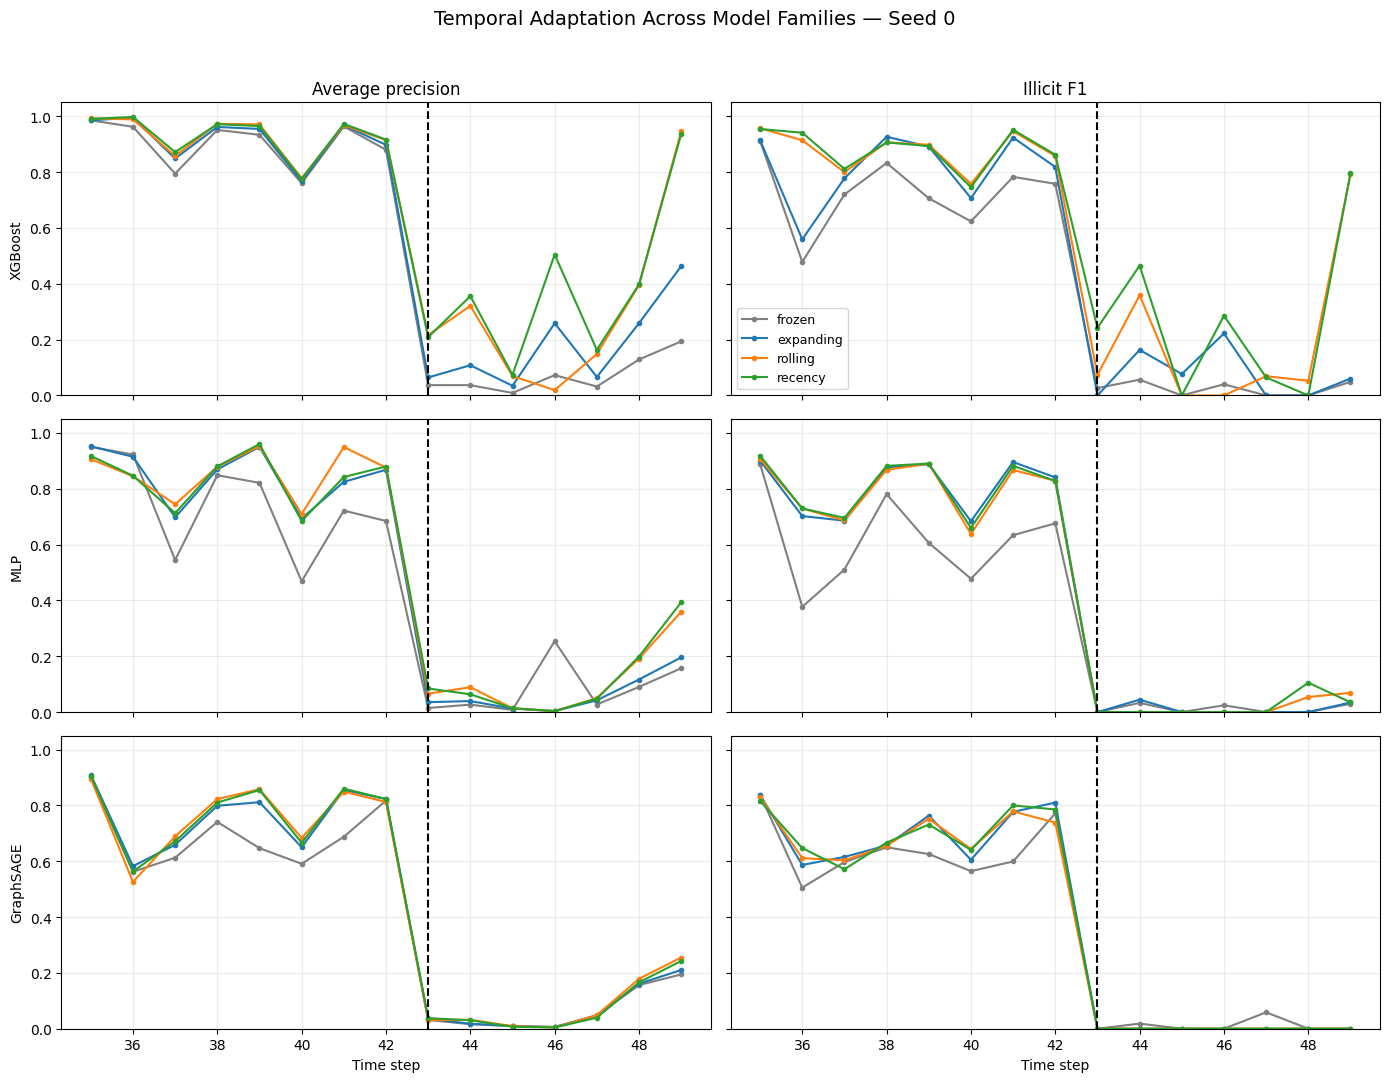

In [ ]:
# Plot adaptation trajectories for every model
policy_colors = {
    "frozen": "gray",
    "expanding": "tab:blue",
    "rolling": "tab:orange",
    "recency": "tab:green",
}

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 11),
    sharex=True,
    sharey=True,
)

for row, model_name in enumerate(
    ["XGBoost", "MLP", "GraphSAGE"]
):
    model_results = all_seed0_metrics.loc[
        all_seed0_metrics["model"].eq(model_name)
    ]

    for policy in ["frozen", "expanding", "rolling", "recency"]:
        subset = model_results.loc[
            model_results["policy"].eq(policy)
        ].sort_values("time_step")

        for column, metric in enumerate(
            ["average_precision", "f1"]
        ):
            axes[row, column].plot(
                subset["time_step"],
                subset[metric],
                marker="o",
                markersize=3,
                color=policy_colors[policy],
                label=policy,
            )

    axes[row, 0].set_ylabel(model_name)

    for ax in axes[row]:
        ax.axvline(43, color="black", linestyle="--")
        ax.set_ylim(0, 1.05)
        ax.grid(alpha=0.25)

axes[0, 0].set_title("Average precision")
axes[0, 1].set_title("Illicit F1")

for ax in axes[-1]:
    ax.set_xlabel("Time step")

axes[0, 1].legend(fontsize=9)

fig.suptitle(
    "Temporal Adaptation Across Model Families — Seed 0",
    fontsize=14,
)

fig.tight_layout(rect=[0, 0, 1, 0.96])

fig.savefig(
    RESULTS_DIR / "all_models_adaptation_trajectories_seed0.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

Package your saved results:

In [ ]:
import shutil
from google.colab import files

assert RESULTS_DIR.is_dir()

saved_files = [
    path for path in RESULTS_DIR.rglob("*")
    if path.is_file()
]

print("Result files found:", len(saved_files))

archive_path = shutil.make_archive(
    base_name=str(PROJECT_DIR / "AML_GNN_Seed0_Results"),
    format="zip",
    root_dir=str(RESULTS_DIR),
)

print("Created:", archive_path)

files.download(archive_path)

Result files found: 50
Created: /content/drive/MyDrive/Colab Notebooks/AML_GNN_Project/AML_GNN_Seed0_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>